# Wallet-market anomaly analysis and wallet segmentation

The goal of this notebook is to analyze wallet behavior in a tech-category prediction-market event:

1. Load markets, settlements, and trade-level wallet trades;
2. Clean the trade records and build wallet-market features;
3. Run EDA on trade size, timing, and market concentration;
4. Use Isolation Forest / PCA to identify anomalous wallet-markets;
5. Use K-Means to group wallets into different trader types;
6. Compare win rates and calibration gaps across types;
7. Save the cleaned datasets and the PPT figures.

Important note: neither anomaly scores nor win rates alone can prove insider behavior. `win` is used only for post-hoc evaluation and is not an input to the real-time anomaly detection model.


In [37]:
# If dependencies are missing, run in the notebook:
# %pip install pandas numpy scikit-learn matplotlib seaborn psycopg2-binary pyarrow

import os
from pathlib import Path
from urllib.parse import quote
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import duckdb

pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 160)

# Load .env from the current directory or the notebook directory; passwords are never written into the notebook.
def load_simple_env(path):
    path = Path(path)
    if not path.exists():
        return
    for line in path.read_text().splitlines():
        line = line.strip()
        if not line or line.startswith('#') or '=' not in line:
            continue
        key, value = line.split('=', 1)
        os.environ.setdefault(key.strip(), value.strip().strip('\"').strip("'"))

for env_path in [Path.cwd() / '.env', Path.cwd() / 'notebooks' / '.env', Path.cwd().parent / '.env']:
    load_simple_env(env_path)

TRADES_PATH = os.getenv('TRADES_PATH', '')
EVENT_SLUG = 'which-company-has-best-ai-model-end-of-june'
TRADE_START = '2026-06-01'
TRADE_END = '2026-06-30'
CF_USER = os.getenv('CF_USER')
CF_PASS = os.getenv('CF_PASS')
if not CF_USER or not CF_PASS:
    raise RuntimeError('Please set CF_USER and CF_PASS in .env.')
CLOUDFRONT_BASE = (
    f'https://{quote(CF_USER, safe="")}:{quote(CF_PASS, safe="")}@'
    'd1yyqbluk0oz0t.cloudfront.net'
)
RANDOM_STATE = 42

# Unified output directory: all datasets and figures are saved to the notebook folder.
candidate_dirs = [Path(os.getenv('NOTEBOOK_DIR', ''))] if os.getenv('NOTEBOOK_DIR') else []
candidate_dirs += [Path.cwd(), Path.cwd() / 'notebooks', Path.cwd().parent / 'notebooks']
NOTEBOOK_DIR = next(
    (p for p in candidate_dirs if p and p.exists() and (p / '.env').exists()),
    Path.cwd()
)
NOTEBOOK_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR = NOTEBOOK_DIR / 'figures'
DATASET_DIR = NOTEBOOK_DIR / 'datasets'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
DATASET_DIR.mkdir(parents=True, exist_ok=True)


## 1. Connect to Supabase and load the markets/settlement tables

This notebook reads `JUNE_DB_URL` from `.env`; `SUPABASE_DSN` is also supported. Do not write passwords directly into the notebook.

In [38]:
from sqlalchemy import create_engine, text

SUPABASE_DSN = os.getenv('JUNE_DB_URL') or os.getenv('SUPABASE_DSN')
if not SUPABASE_DSN:
    raise RuntimeError('Please set JUNE_DB_URL in .env, or set the SUPABASE_DSN environment variable.')
if 'sslmode=' not in SUPABASE_DSN:
    SUPABASE_DSN += ('&' if '?' in SUPABASE_DSN else '?') + 'sslmode=require'

engine = create_engine(
    SUPABASE_DSN,
    connect_args={"sslmode": "require", "options": "-c statement_timeout=300000"},
    pool_pre_ping=True,
)

def read_sql(sql, params=None):
    return pd.read_sql_query(text(sql), engine, params=params)

tables = read_sql("""
    SELECT table_schema, table_name
    FROM information_schema.tables
    WHERE table_schema = 'public'
    ORDER BY table_name
""")
tables

,table_schema,table_name
0,public,events
1,public,market_hourly
2,public,markets
3,public,resolutions
4,public,wallet_pseudonym_map


In [3]:
# Load only the target event's markets, to avoid scanning 1.5 million market records at once.
markets = read_sql("""
    SELECT slug, title, event_slug, start_date, end_date, active, closed,
           last_trade_price, best_bid, best_ask, volume_clob, volume_24hr,
           volume_1wk, volume_1mo, outcomes
    FROM public.markets
    WHERE event_slug = :event_slug
""", {"event_slug": EVENT_SLUG})

resolutions = read_sql("""
    SELECT market_slug, resolved_yes, price_at_close, price_24h_before,
           resolved_at, uma_resolution_status
    FROM public.resolutions
    WHERE market_slug IN (
        SELECT slug FROM public.markets WHERE event_slug = :event_slug
    )
""", {"event_slug": EVENT_SLUG})

markets['start_date'] = pd.to_datetime(markets['start_date'], utc=True)
markets['end_date'] = pd.to_datetime(markets['end_date'], utc=True)
resolutions['resolved_at'] = pd.to_datetime(resolutions['resolved_at'], utc=True)
print('markets:', markets.shape)
print('resolutions:', resolutions.shape)
markets.head()

markets: (15, 15)
resolutions: (15, 6)


,slug,title,event_slug,start_date,end_date,active,closed,last_trade_price,best_bid,best_ask,volume_clob,volume_24hr,volume_1wk,volume_1mo,outcomes
0,will-mistral-have-the-best-ai-model-at-the-end...,Will Mistral have the best AI model at the end...,which-company-has-best-ai-model-end-of-june,2025-10-10 21:52:57.992000+00:00,2026-06-30 00:00:00+00:00,True,False,0.001,NaN,0.001,1.048485e+06,10.010000,28261.200000,4.386253e+05,"[Yes, No]"
1,will-bytedance-have-the-best-ai-model-at-the-e...,Will ByteDance have the best AI model at the e...,which-company-has-best-ai-model-end-of-june,2025-10-10 21:53:00.231000+00:00,2026-06-30 00:00:00+00:00,True,False,0.001,NaN,0.001,7.911797e+05,NaN,NaN,NaN,"[Yes, No]"
2,will-anthropic-have-the-best-ai-model-at-the-e...,Will Anthropic have the best AI model at the e...,which-company-has-best-ai-model-end-of-june,2025-10-10 21:52:57.234000+00:00,2026-06-30 00:00:00+00:00,True,False,0.999,0.999,1.000,2.456953e+06,67912.754597,296676.804498,1.297595e+06,"[Yes, No]"
3,will-baidu-have-the-best-ai-model-at-the-end-o...,Will Baidu have the best AI model at the end o...,which-company-has-best-ai-model-end-of-june,2025-10-10 21:52:59.154000+00:00,2026-06-30 00:00:00+00:00,True,False,0.001,NaN,0.001,5.433584e+05,5.000000,13032.860000,2.464990e+05,"[Yes, No]"
4,will-alibaba-have-the-best-ai-model-at-the-end...,Will Alibaba have the best AI model at the end...,which-company-has-best-ai-model-end-of-june,2025-10-10 21:52:56.223000+00:00,2026-06-30 00:00:00+00:00,True,False,0.001,NaN,0.001,1.538936e+06,NaN,NaN,NaN,"[Yes, No]"


## 2. Select the tech-category pilot event

By default this notebook analyzes `which-company-has-best-ai-model-end-of-june`, i.e., which company has the best AI model at the end of June 2026. This event contains several related Yes/No markets, which makes it suitable for showing wallet-market features and anomaly detection in the PPT.

In [4]:
event_summary = (
    markets.dropna(subset=['event_slug'])
    .groupby('event_slug')
    .agg(markets=('slug', 'nunique'),
         closed_markets=('closed', 'sum'),
         total_volume=('volume_clob', 'sum'))
    .sort_values(['closed_markets', 'total_volume'], ascending=False)
)
print('pilot event:', EVENT_SLUG)
print('pilot markets:', int(event_summary.loc[EVENT_SLUG, 'markets']) if EVENT_SLUG in event_summary.index else 0)
event_summary.head(20)

pilot event: which-company-has-best-ai-model-end-of-june
pilot markets: 15


,markets,closed_markets,total_volume
event_slug,,,
which-company-has-best-ai-model-end-of-june,15,0,2.232305e+07


## 3. Load and standardize the real trade data

After standardization these fields are required: `wallet`, `market`, `timestamp`, `price`, `size`, `direction`, and `trade_side`.

If the data only has order-book fields and no wallet, it cannot go directly into wallet-level analysis.


In [5]:
# User Guide: wallet_trades/trades-<date>.parquet, with fields wallet, market, time, side, outcome, dollars.
# If TRADES_PATH is set, read the local file first; otherwise read the target month from CloudFront.
market_totals = None
if TRADES_PATH:
    path = Path(TRADES_PATH)
    if path.suffix.lower() == '.csv':
        trades = pd.read_csv(path)
    elif path.suffix.lower() in {'.parquet', '.pq'}:
        trades = pd.read_parquet(path)
    else:
        raise ValueError('Only CSV or Parquet is supported')
else:
    dates = pd.date_range(TRADE_START, TRADE_END, freq='D').strftime('%Y-%m-%d').tolist()
    urls = [f'{CLOUDFRONT_BASE}/wallet_trades/trades-{d}.parquet' for d in dates]
    url_list = '[' + ','.join(repr(u) for u in urls) + ']'
    trade_con = duckdb.connect()
    trade_con.execute('INSTALL httpfs; LOAD httpfs;')
    # First aggregate only the amount per wallet-market, as the market-wide baseline for within_size.
    market_totals = trade_con.execute(f'''
        SELECT wallet, market, SUM(dollars) AS market_dollars
        FROM read_parquet({url_list})
        WHERE upper(side) = 'BUY'
        GROUP BY wallet, market
    ''').df()
    # Then read the target event's trade-level fills, to avoid loading all historical trades into pandas.
    pilot_markets = markets.loc[markets['event_slug'].eq(EVENT_SLUG), 'slug'].dropna().tolist()
    trade_con.register('pilot_markets', pd.DataFrame({'market': pilot_markets}))
    trades = trade_con.execute(f'''
        SELECT t.wallet, t.market, t.time, t.side, t.outcome, t.price, t.size, t.dollars
        FROM read_parquet({url_list}) t
        JOIN pilot_markets p ON p.market = t.market
    ''').df()
    trades = trades.rename(columns={'time': 'timestamp', 'side': 'trade_side', 'outcome': 'direction', 'dollars': 'notional'})

print(trades.shape)
print(trades.columns.tolist())
print('wallets:', trades['wallet'].nunique(), 'markets:', trades['market'].nunique())
trades.head()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

(61829, 8)
['wallet', 'market', 'timestamp', 'trade_side', 'direction', 'price', 'size', 'notional']
wallets: 10625 markets: 15


,wallet,market,timestamp,trade_side,direction,price,size,notional
0,0x90a240afe5b0141c90715713417fdcfca47a38b0,will-bytedance-have-the-best-ai-model-at-the-e...,2026-06-03 16:52:54-07:00,SELL,No,0.998,1.750,1.746500
1,0x656456832595eded6e5444bf66f48b720e6d6f1f,will-bytedance-have-the-best-ai-model-at-the-e...,2026-06-03 16:51:34-07:00,BUY,No,0.999,1.051,1.049949
2,0x1fb831c9dfde7a878605c32a2a234bb0011269fa,will-bytedance-have-the-best-ai-model-at-the-e...,2026-06-03 16:48:43-07:00,SELL,No,0.998,20.160,20.119680
3,0x1fb831c9dfde7a878605c32a2a234bb0011269fa,will-bytedance-have-the-best-ai-model-at-the-e...,2026-06-03 16:48:15-07:00,BUY,No,0.999,20.160,20.139840
4,0x1fb831c9dfde7a878605c32a2a234bb0011269fa,will-bytedance-have-the-best-ai-model-at-the-e...,2026-06-03 16:47:22-07:00,SELL,No,0.998,19.450,19.411100


In [6]:
# Modify this mapping according to the fields in your real file.
COLUMN_MAP = {
    'wallet_address': 'wallet',
    'market_slug': 'market',
    'ts': 'timestamp',
    'ts_ms': 'timestamp_ms',
    'outcome': 'direction',
    'token_side': 'direction',
    'side': 'trade_side',
}

for old, new in COLUMN_MAP.items():
    if old in trades.columns and new not in trades.columns:
        trades = trades.rename(columns={old: new})

if 'timestamp' not in trades.columns and 'timestamp_ms' in trades.columns:
    trades['timestamp'] = pd.to_datetime(trades['timestamp_ms'], unit='ms', utc=True)
elif 'timestamp' in trades.columns:
    trades['timestamp'] = pd.to_datetime(trades['timestamp'], utc=True)

required = {'wallet', 'market', 'timestamp', 'price', 'size', 'direction', 'trade_side'}
missing = required - set(trades.columns)
if missing:
    raise ValueError(f'Missing fields required for wallet-level analysis: {sorted(missing)}')

trades['direction'] = trades['direction'].astype(str).str.upper()
trades['trade_side'] = trades['trade_side'].astype(str).str.upper()
trades = trades[trades['direction'].isin(['YES', 'NO'])].copy()
trades['notional'] = trades['price'].astype(float) * trades['size'].abs().astype(float)
trades['signed_notional'] = np.where(trades['trade_side'].eq('BUY'), trades['notional'], -trades['notional'])
trades = trades.dropna(subset=['wallet', 'market', 'timestamp', 'notional'])
trades.head()

,wallet,market,timestamp,trade_side,direction,price,size,notional,signed_notional
0,0x90a240afe5b0141c90715713417fdcfca47a38b0,will-bytedance-have-the-best-ai-model-at-the-e...,2026-06-03 23:52:54+00:00,SELL,NO,0.998,1.750,1.746500,-1.746500
1,0x656456832595eded6e5444bf66f48b720e6d6f1f,will-bytedance-have-the-best-ai-model-at-the-e...,2026-06-03 23:51:34+00:00,BUY,NO,0.999,1.051,1.049949,1.049949
2,0x1fb831c9dfde7a878605c32a2a234bb0011269fa,will-bytedance-have-the-best-ai-model-at-the-e...,2026-06-03 23:48:43+00:00,SELL,NO,0.998,20.160,20.119680,-20.119680
3,0x1fb831c9dfde7a878605c32a2a234bb0011269fa,will-bytedance-have-the-best-ai-model-at-the-e...,2026-06-03 23:48:15+00:00,BUY,NO,0.999,20.160,20.139840,20.139840
4,0x1fb831c9dfde7a878605c32a2a234bb0011269fa,will-bytedance-have-the-best-ai-model-at-the-e...,2026-06-03 23:47:22+00:00,SELL,NO,0.998,19.450,19.411100,-19.411100


## 4. Data quality audit and deduplication

Complete the data quality checks before any feature computation. Fully duplicated trades are removed; trades with the same wallet-market-time but a different amount or price are kept.


In [7]:
# Data quality audit

audit = pd.DataFrame({
    "metric": [
        "total trades",
        "unique wallets",
        "unique markets",
        "duplicate rows",
        "missing wallet",
        "missing market",
        "missing timestamp",
        "missing price",
        "missing size",
        "price outside [0, 1]",
        "size <= 0",
        "notional <= 0",
        "duplicate wallet-market-time"
    ],
    "value": [
        len(trades),
        trades["wallet"].nunique(),
        trades["market"].nunique(),
        trades.duplicated().sum(),
        trades["wallet"].isna().sum(),
        trades["market"].isna().sum(),
        trades["timestamp"].isna().sum(),
        trades["price"].isna().sum(),
        trades["size"].isna().sum(),
        (~trades["price"].between(0, 1)).sum(),
        (trades["size"] <= 0).sum(),
        (trades["notional"] <= 0).sum(),
        trades.duplicated(
            subset=["wallet", "market", "timestamp"]
        ).sum()
    ]
})

display(audit)

,metric,value
0,total trades,61829
1,unique wallets,10625
2,unique markets,15
3,duplicate rows,416
4,missing wallet,0
5,missing market,0
6,missing timestamp,0
7,missing price,0
8,missing size,0
9,"price outside [0, 1]",0


In [8]:
# Inspect duplicate records before deciding what to remove

# 1. Fully duplicated records
exact_duplicates = trades[
    trades.duplicated(keep=False)
].sort_values(
    ["wallet", "market", "timestamp"]
)

print("Exact duplicate rows:", len(exact_duplicates))

display(
    exact_duplicates.head(10)
)


# 2. wallet-market-time duplicated records
key_cols = ["wallet", "market", "timestamp"]

key_duplicate_groups = (
    trades
    .groupby(key_cols)
    .size()
    .reset_index(name="rows_at_same_time")
)

key_duplicate_groups = key_duplicate_groups[
    key_duplicate_groups["rows_at_same_time"] > 1
].sort_values(
    "rows_at_same_time",
    ascending=False
)

print(
    "Repeated wallet-market-time groups:",
    len(key_duplicate_groups)
)

display(
    key_duplicate_groups.head(10)
)


# Inspect the individual trades within one wallet-market-time group
if len(key_duplicate_groups) > 0:
    example_key = key_duplicate_groups.iloc[0]

    example_rows = trades[
        (trades["wallet"] == example_key["wallet"]) &
        (trades["market"] == example_key["market"]) &
        (trades["timestamp"] == example_key["timestamp"])
    ]

    display(example_rows)

Exact duplicate rows: 784


,wallet,market,timestamp,trade_side,direction,price,size,notional,signed_notional
43519,0x0fac0cd673a07018dcc34f04a3e7d8c80f659330,will-anthropic-have-the-best-ai-model-at-the-e...,2026-06-19 13:42:10+00:00,BUY,NO,0.041,30.0,1.23,1.23
43526,0x0fac0cd673a07018dcc34f04a3e7d8c80f659330,will-anthropic-have-the-best-ai-model-at-the-e...,2026-06-19 13:42:10+00:00,BUY,NO,0.041,30.0,1.23,1.23
20538,0x0fac0cd673a07018dcc34f04a3e7d8c80f659330,will-bytedance-have-the-best-ai-model-at-the-e...,2026-06-09 15:40:57+00:00,BUY,NO,0.999,30.0,29.97,29.97
20540,0x0fac0cd673a07018dcc34f04a3e7d8c80f659330,will-bytedance-have-the-best-ai-model-at-the-e...,2026-06-09 15:40:57+00:00,BUY,NO,0.999,30.0,29.97,29.97
7498,0x0fac0cd673a07018dcc34f04a3e7d8c80f659330,will-google-have-the-best-ai-model-at-the-end-...,2026-06-02 12:39:05+00:00,BUY,NO,0.870,30.0,26.10,26.10
7500,0x0fac0cd673a07018dcc34f04a3e7d8c80f659330,will-google-have-the-best-ai-model-at-the-end-...,2026-06-02 12:39:05+00:00,BUY,NO,0.870,30.0,26.10,26.10
7491,0x0fac0cd673a07018dcc34f04a3e7d8c80f659330,will-google-have-the-best-ai-model-at-the-end-...,2026-06-02 12:41:08+00:00,BUY,NO,0.870,30.0,26.10,26.10
7494,0x0fac0cd673a07018dcc34f04a3e7d8c80f659330,will-google-have-the-best-ai-model-at-the-end-...,2026-06-02 12:41:08+00:00,BUY,NO,0.870,30.0,26.10,26.10
7467,0x0fac0cd673a07018dcc34f04a3e7d8c80f659330,will-google-have-the-best-ai-model-at-the-end-...,2026-06-02 12:44:29+00:00,BUY,NO,0.870,30.0,26.10,26.10
7468,0x0fac0cd673a07018dcc34f04a3e7d8c80f659330,will-google-have-the-best-ai-model-at-the-end-...,2026-06-02 12:44:29+00:00,BUY,NO,0.870,30.0,26.10,26.10


Repeated wallet-market-time groups: 1318


,wallet,market,timestamp,rows_at_same_time
29731,0x7ff19bba9e753d74ffb6bf40c0a452f54dc9b73b,will-google-have-the-best-ai-model-at-the-end-...,2026-06-19 23:34:44+00:00,9
28398,0x76accbfcc5c56b7dca03b04cfc5a162554144325,will-xai-have-the-best-ai-model-at-the-end-of-...,2026-06-19 13:42:10+00:00,9
29674,0x7ff19bba9e753d74ffb6bf40c0a452f54dc9b73b,will-google-have-the-best-ai-model-at-the-end-...,2026-06-12 21:34:21+00:00,8
26987,0x76accbfcc5c56b7dca03b04cfc5a162554144325,will-meta-have-the-best-ai-model-at-the-end-of...,2026-06-19 13:42:10+00:00,6
28383,0x76accbfcc5c56b7dca03b04cfc5a162554144325,will-xai-have-the-best-ai-model-at-the-end-of-...,2026-06-18 16:49:58+00:00,6
24188,0x71a23b86b5a456060989a65f49fbdb101389bef9,will-meta-have-the-best-ai-model-at-the-end-of...,2026-06-09 01:56:03+00:00,6
47984,0xd8d5fa05b9c03fa1559e84271810d0f31b29af38,will-google-have-the-best-ai-model-at-the-end-...,2026-06-09 15:29:54+00:00,5
40582,0xad2c5682a7e9100f381d1ffffda21f886709b6b9,will-meta-have-the-best-ai-model-at-the-end-of...,2026-06-14 17:36:13+00:00,5
29701,0x7ff19bba9e753d74ffb6bf40c0a452f54dc9b73b,will-google-have-the-best-ai-model-at-the-end-...,2026-06-15 01:31:09+00:00,5
28420,0x76accbfcc5c56b7dca03b04cfc5a162554144325,will-xai-have-the-best-ai-model-at-the-end-of-...,2026-06-19 23:34:14+00:00,5


,wallet,market,timestamp,trade_side,direction,price,size,notional,signed_notional
46994,0x7ff19bba9e753d74ffb6bf40c0a452f54dc9b73b,will-google-have-the-best-ai-model-at-the-end-...,2026-06-19 23:34:44+00:00,BUY,YES,0.038,25.5,0.969,0.969
46995,0x7ff19bba9e753d74ffb6bf40c0a452f54dc9b73b,will-google-have-the-best-ai-model-at-the-end-...,2026-06-19 23:34:44+00:00,BUY,YES,0.038,25.5,0.969,0.969
46996,0x7ff19bba9e753d74ffb6bf40c0a452f54dc9b73b,will-google-have-the-best-ai-model-at-the-end-...,2026-06-19 23:34:44+00:00,BUY,YES,0.038,25.5,0.969,0.969
46997,0x7ff19bba9e753d74ffb6bf40c0a452f54dc9b73b,will-google-have-the-best-ai-model-at-the-end-...,2026-06-19 23:34:44+00:00,BUY,YES,0.038,25.5,0.969,0.969
46998,0x7ff19bba9e753d74ffb6bf40c0a452f54dc9b73b,will-google-have-the-best-ai-model-at-the-end-...,2026-06-19 23:34:44+00:00,BUY,YES,0.038,35.0,1.330,1.330
46999,0x7ff19bba9e753d74ffb6bf40c0a452f54dc9b73b,will-google-have-the-best-ai-model-at-the-end-...,2026-06-19 23:34:44+00:00,BUY,YES,0.038,25.5,0.969,0.969
47000,0x7ff19bba9e753d74ffb6bf40c0a452f54dc9b73b,will-google-have-the-best-ai-model-at-the-end-...,2026-06-19 23:34:44+00:00,BUY,YES,0.038,25.5,0.969,0.969
47001,0x7ff19bba9e753d74ffb6bf40c0a452f54dc9b73b,will-google-have-the-best-ai-model-at-the-end-...,2026-06-19 23:34:44+00:00,BUY,YES,0.038,25.5,0.969,0.969
47002,0x7ff19bba9e753d74ffb6bf40c0a452f54dc9b73b,will-google-have-the-best-ai-model-at-the-end-...,2026-06-19 23:34:44+00:00,BUY,YES,0.038,25.5,0.969,0.969


In [9]:
# Remove only fully duplicated trade records

trades_before = len(trades)

trades = trades.drop_duplicates().copy()

trades_after = len(trades)
removed_rows = trades_before - trades_after

print(f"Rows before cleaning: {trades_before:,}")
print(f"Rows after cleaning:  {trades_after:,}")
print(f"Exact duplicates removed: {removed_rows:,}")
print(f"Removal rate: {removed_rows / trades_before:.2%}")

# Make the later within_size baseline also use the deduplicated trades.
market_totals = None


Rows before cleaning: 61,829
Rows after cleaning:  61,413
Exact duplicates removed: 416
Removal rate: 0.67%


In [10]:
# Bot / market-maker screen (data processing). Wallets with >= BOT_TRADES trades are removed from `trades`.
import pandas as pd

BOT_TRADES = 2000          # same rule of thumb as the lab demo
APPLY_BOT_FILTER = True    # True = remove these wallets from `trades` for all later steps

if 'trades_all' in globals():
    trades = trades_all.copy()      # re-run safe: start again from the full table

trade_counts = trades.groupby('wallet').size()
for t in (100, 200, 500, 1000, 2000):
    print(f'wallets with >= {t:>4} trades: {int((trade_counts >= t).sum())}')

bot_wallets = set(trade_counts[trade_counts >= BOT_TRADES].index)
bot_buy = trades.loc[trades['wallet'].isin(bot_wallets) & trades['trade_side'].eq('BUY'), 'notional'].sum()
all_buy = trades.loc[trades['trade_side'].eq('BUY'), 'notional'].sum()
print(f'\nbots at >= {BOT_TRADES} trades: {len(bot_wallets)} | '
      f'their trade rows: {int(trades["wallet"].isin(bot_wallets).sum()):,} of {len(trades):,} | '
      f'their BUY dollars: {bot_buy / all_buy:.1%}')
top = trade_counts.sort_values(ascending=False).head(10).rename('trades').reset_index()
top['market_count'] = top['wallet'].map(trades.groupby('wallet')['market'].nunique())
display(top)

if APPLY_BOT_FILTER:
    trades_all = trades.copy()                                 # keep the full table for reference
    trades = trades[~trades['wallet'].isin(bot_wallets)].copy()
    print(f'filtered: {len(trades_all):,} -> {len(trades):,} trade rows, wallets removed: {len(bot_wallets)}')

wallets with >=  100 trades: 47
wallets with >=  200 trades: 41
wallets with >=  500 trades: 29
wallets with >= 1000 trades: 8
wallets with >= 2000 trades: 3

bots at >= 2000 trades: 3 | their trade rows: 10,636 of 61,413 | their BUY dollars: 41.7%


,wallet,trades,market_count
0,0x76accbfcc5c56b7dca03b04cfc5a162554144325,4701,15
1,0xe04be250fbbdfc5457fe4da9c84042c5d77e7949,3865,15
2,0xde4a310f0ad8a4b264878a18e833ff30e1082a63,2070,15
3,0xa754b92c89c3e3a59fc43c04dc0b05fb2398db61,1558,11
4,0x4582e2e1bf94b8d620053c426208ed3e40201b30,1412,15
5,0xe5eb0915873ab76fe78c960ed340f72a91dd7e3d,1319,15
6,0x291f6a4f9ad3796fd0adaa0b2a5ac9922422e7eb,1215,15
7,0x1ddd705e75d882cd6442fe2f68ec9c36b7013a1c,1118,15
8,0x0fac0cd673a07018dcc34f04a3e7d8c80f659330,890,15
9,0xb4b5bf2c0c1993b1346b307010e49336719c7524,755,15


filtered: 61,413 -> 50,777 trade rows, wallets removed: 3


## 4. Basic exploratory data analysis

First look at wallet size, wallet concentration, market amounts, and the distribution of trade times.


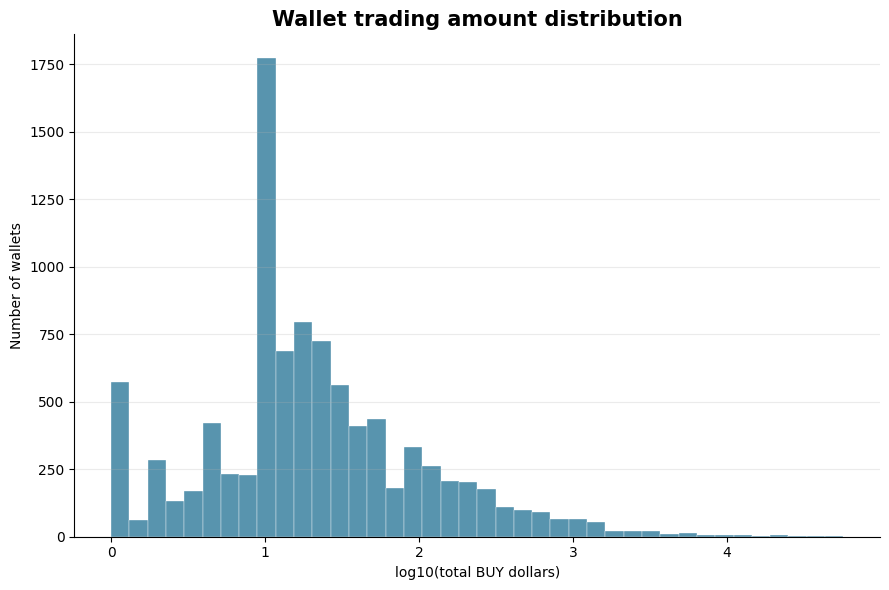

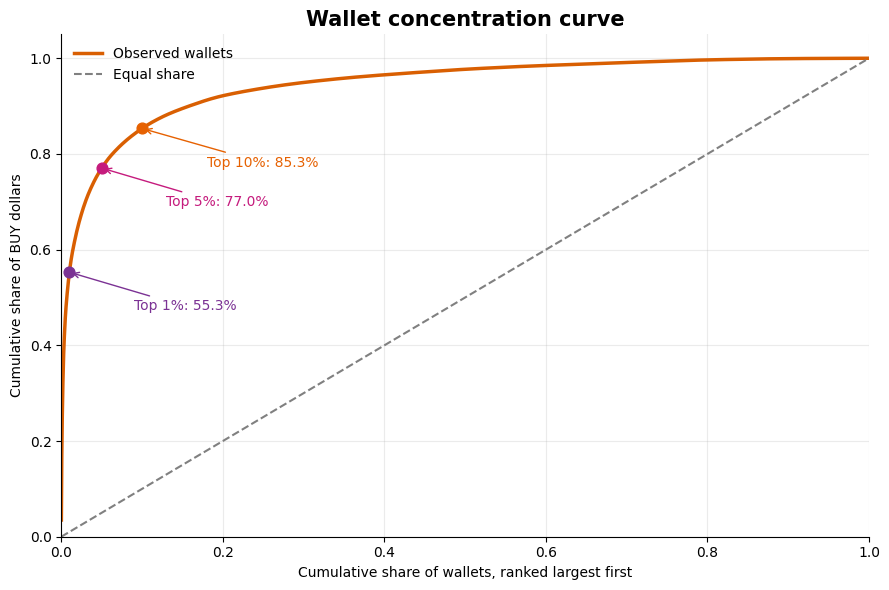

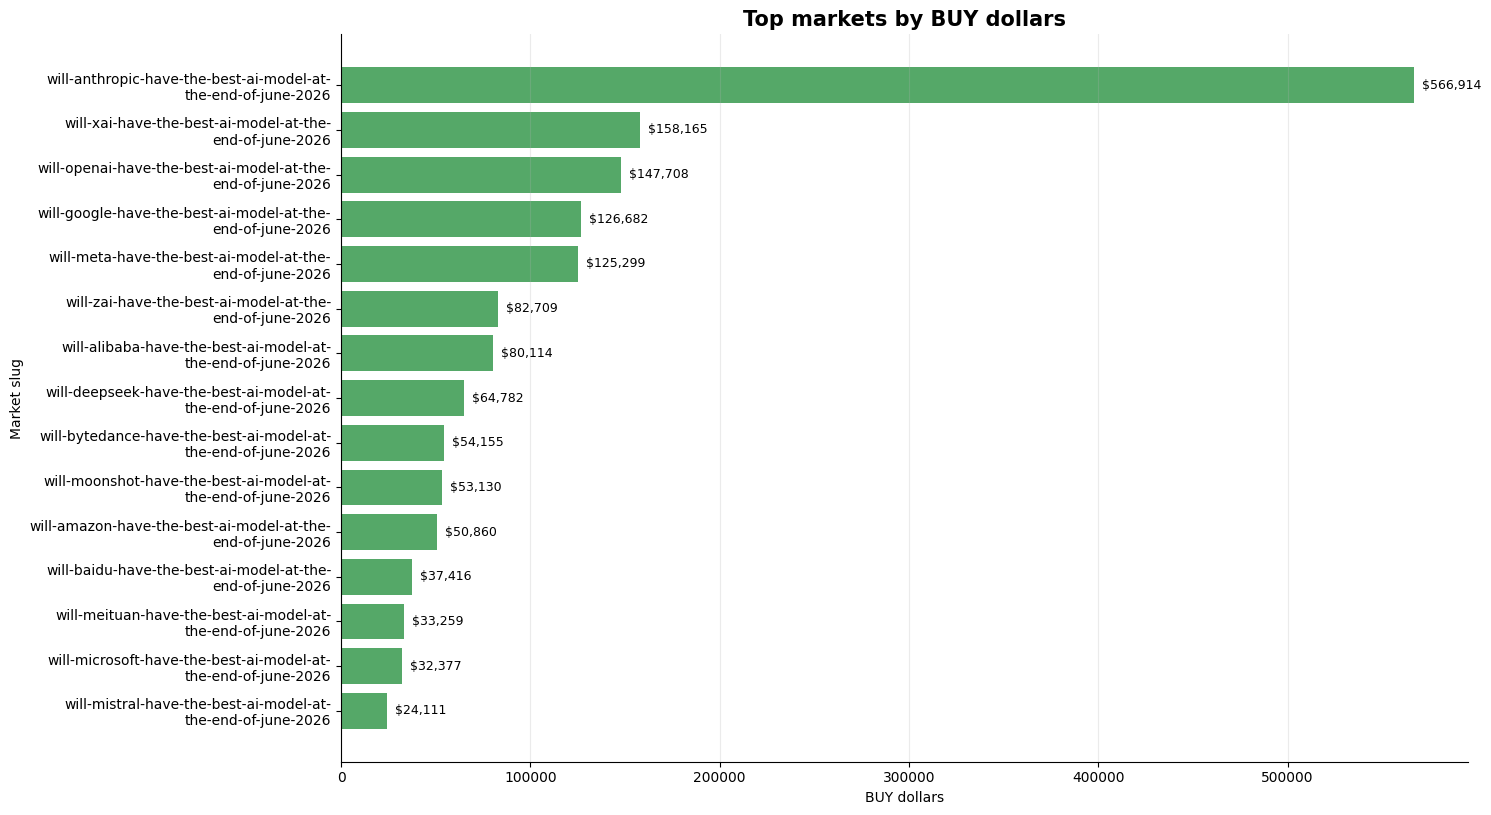

Saved figures to:
/Users/zhongyangfan/Desktop/L3_prediction_markets_student_package_2026-10-07/notebooks/figures


In [11]:
# EDA 1: wallet amounts, wallet concentration, and market amounts

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from textwrap import fill

# Use BUY trades only, and re-aggregate on the cleaned trades.
buy_eda = trades[trades['trade_side'].eq('BUY')].copy()

wallet_summary = (
    buy_eda.groupby('wallet', as_index=False)
    .agg(total_dollars=('notional', 'sum'), n_trades=('notional', 'size'))
)

market_summary = (
    buy_eda.groupby('market', as_index=False)
    .agg(total_dollars=('notional', 'sum'), n_trades=('notional', 'size'))
)

output_dir = NOTEBOOK_DIR
figure_dir = FIGURE_DIR

# ==================================================
# Figure 1: distribution of wallet trade amounts
# ==================================================

fig, ax = plt.subplots(figsize=(9, 6))

ax.hist(
    np.log10(wallet_summary["total_dollars"].clip(lower=1)),
    bins=40,
    color="#3B82A0",
    alpha=0.85,
    edgecolor="white",
    linewidth=0.3
)

ax.set_title(
    "Wallet trading amount distribution",
    fontsize=15,
    fontweight="bold"
)
ax.set_xlabel("log10(total BUY dollars)")
ax.set_ylabel("Number of wallets")
ax.grid(axis="y", alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
fig.savefig(
    figure_dir / "01_wallet_amount_distribution.png",
    dpi=240,
    bbox_inches="tight"
)
plt.show()


# ==================================================
# Figure 2: wallet concentration curve
# ==================================================

amounts = wallet_summary["total_dollars"].sort_values(
    ascending=False
).to_numpy()

cum_dollars = np.cumsum(amounts) / amounts.sum()
cum_wallets = np.arange(1, len(amounts) + 1) / len(amounts)

fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(
    cum_wallets,
    cum_dollars,
    color="#D95F02",
    linewidth=2.5,
    label="Observed wallets"
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    linewidth=1.5,
    label="Equal share"
)

for pct, color in [
    (0.01, "#7B3294"),
    (0.05, "#C51B7D"),
    (0.10, "#E66101")
]:
    idx = max(1, int(np.ceil(len(amounts) * pct))) - 1
    share = cum_dollars[idx]

    ax.scatter(
        pct,
        share,
        color=color,
        s=60,
        zorder=5
    )

    ax.annotate(
        f"Top {pct:.0%}: {share:.1%}",
        xy=(pct, share),
        xytext=(pct + 0.08, share - 0.08),
        arrowprops=dict(
            arrowstyle="->",
            color=color,
            lw=1
        ),
        fontsize=10,
        color=color
    )

ax.set_title(
    "Wallet concentration curve",
    fontsize=15,
    fontweight="bold"
)
ax.set_xlabel("Cumulative share of wallets, ranked largest first")
ax.set_ylabel("Cumulative share of BUY dollars")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.05)
ax.legend(frameon=False)
ax.grid(alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
fig.savefig(
    figure_dir / "02_wallet_concentration_curve.png",
    dpi=240,
    bbox_inches="tight"
)
plt.show()


# ==================================================
# Figure 3: BUY amount per market
# Keep the full slug, and wrap lines automatically
# ==================================================

top_markets = (
    market_summary
    .sort_values("total_dollars", ascending=False)
    .head(15)
    .sort_values("total_dollars")
    .copy()
)

top_markets["slug_label"] = top_markets["market"].map(
    lambda x: fill(str(x), width=42)
)

fig_height = max(8, len(top_markets) * 0.55)

fig, ax = plt.subplots(figsize=(15, fig_height))

bars = ax.barh(
    top_markets["slug_label"],
    top_markets["total_dollars"],
    color="#55A868"
)

ax.set_title(
    "Top markets by BUY dollars",
    fontsize=15,
    fontweight="bold"
)
ax.set_xlabel("BUY dollars")
ax.set_ylabel("Market slug")
ax.grid(axis="x", alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)

for bar, value in zip(bars, top_markets["total_dollars"]):
    ax.text(
        bar.get_width(),
        bar.get_y() + bar.get_height() / 2,
        f"  ${value:,.0f}",
        va="center",
        fontsize=9
    )

fig.tight_layout()
fig.savefig(
    figure_dir / "03_market_buy_dollars_full_slugs.png",
    dpi=240,
    bbox_inches="tight"
)
plt.show()

print("Saved figures to:")
print(figure_dir)

## 4B. Outcomes, positions and price calibration

- **position**: the side (YES or NO) where a wallet put more BUY dollars in a market; held to resolution, SELLs ignored.
- **price paid**: dollar-weighted average price of that side, i.e. the implied win probability.
- **win**: whether that side turned out correct. **excess win rate = win - price paid**.
- CIs are a bootstrap that resamples whole markets (positions in one market are correlated).

Outcomes are used only to evaluate scores after the fact, never as a model input.

In [12]:
# Outcome table and wallet-market positions (used ONLY for post-hoc evaluation, never as a model input)
import numpy as np
import pandas as pd

# 1) Market outcome: prefer resolutions.resolved_yes; if the event is not closed yet,
#    fall back to a provisional outcome from last_trade_price (>=0.95 -> YES, <=0.05 -> NO).
outcome = markets[['slug', 'last_trade_price', 'end_date', 'volume_clob']].rename(columns={'slug': 'market'})
outcome = outcome.merge(
    resolutions[['market_slug', 'resolved_yes', 'resolved_at']].rename(columns={'market_slug': 'market'}),
    on='market', how='left')
outcome['resolved_yes'] = pd.to_numeric(outcome['resolved_yes'], errors='coerce')
provisional = np.where(outcome['last_trade_price'] >= 0.95, 1.0,
                       np.where(outcome['last_trade_price'] <= 0.05, 0.0, np.nan))
outcome['yes_outcome'] = outcome['resolved_yes'].fillna(pd.Series(provisional, index=outcome.index))
outcome['outcome_source'] = np.where(outcome['resolved_yes'].notna(), 'resolutions', 'last_trade_price (provisional)')
outcome['short'] = (outcome['market'].str.replace('will-', '', regex=False)
                    .str.split('-have-').str[0])
display(outcome[['short', 'last_trade_price', 'resolved_yes', 'yes_outcome', 'outcome_source']]
        .sort_values('yes_outcome', ascending=False))
print('markets with outcome:', int(outcome['yes_outcome'].notna().sum()), '/', len(outcome),
      '| YES outcomes:', int((outcome['yes_outcome'] == 1).sum()))

# 2) One position per wallet-market: the side (YES/NO) with the larger BUY dollars.
#    Assumes the position is held to resolution (SELL trades are ignored here).
b = trades.loc[trades['trade_side'].eq('BUY') & (trades['notional'] > 0)].copy()
b['price_x_notional'] = b['price'] * b['notional']
side = (b.groupby(['wallet', 'market', 'direction'], as_index=False)
          .agg(side_dollars=('notional', 'sum'), pn=('price_x_notional', 'sum')))
side['side_price'] = side['pn'] / side['side_dollars']          # implied win probability paid
tot = (b.groupby(['wallet', 'market'], as_index=False)
         .agg(buy_dollars=('notional', 'sum'), n_trades=('notional', 'size')))
pos = (side.sort_values('side_dollars', ascending=False)
           .drop_duplicates(['wallet', 'market'])
           .drop(columns='pn')
           .merge(tot, on=['wallet', 'market']))
pos['one_sided_share'] = pos['side_dollars'] / pos['buy_dollars']

# dollar-weighted trade time, expressed as hours before the market end_date
b = b.merge(outcome[['market', 'end_date']], on='market', how='left')
b['hours_to_end'] = (b['end_date'] - b['timestamp']).dt.total_seconds() / 3600
b['h_x_notional'] = b['hours_to_end'] * b['notional']
timing = (b.groupby(['wallet', 'market'], as_index=False)
            .agg(h=('h_x_notional', 'sum'), d=('notional', 'sum')))
timing['hours_to_end'] = timing['h'] / timing['d']
pos = pos.merge(timing[['wallet', 'market', 'hours_to_end']], on=['wallet', 'market'])

pos = pos.merge(outcome[['market', 'yes_outcome']], on='market', how='left')
pos['win'] = np.where(pos['yes_outcome'].isna(), np.nan,
                      (pos['direction'].eq('YES') == pos['yes_outcome'].eq(1.0)).astype(float))
pos['excess'] = pos['win'] - pos['side_price']       # excess win = realised win minus price paid
wm = pos                                              # name used by the later feature cell

ev = pos.dropna(subset=['win'])
print(f'positions: {len(pos):,} | with outcome: {len(ev):,} | wallets: {pos["wallet"].nunique():,}')
print(f'win rate: {ev["win"].mean():.1%} | mean price paid: {ev["side_price"].mean():.1%} | '
      f'excess win rate: {ev["excess"].mean():+.1%}')
display(ev.groupby('direction').agg(positions=('win', 'size'), win_rate=('win', 'mean'),
                                    avg_price=('side_price', 'mean'), excess=('excess', 'mean')).round(3))

,short,last_trade_price,resolved_yes,yes_outcome,outcome_source
2,anthropic,0.999,True,True,resolutions
0,mistral,0.001,False,False,resolutions
1,bytedance,0.001,False,False,resolutions
3,baidu,0.001,False,False,resolutions
4,alibaba,0.001,False,False,resolutions
5,google,0.002,False,False,resolutions
6,amazon,0.001,False,False,resolutions
7,zai,0.001,False,False,resolutions
8,moonshot,0.001,False,False,resolutions
9,deepseek,0.001,False,False,resolutions


markets with outcome: 15 / 15 | YES outcomes: 1
positions: 11,499 | with outcome: 11,499 | wallets: 9,467
win rate: 89.4% | mean price paid: 86.4% | excess win rate: +2.9%


,positions,win_rate,avg_price,excess
direction,,,,
NO,5462,0.949,0.941,0.008
YES,6037,0.843,0.796,0.048


,short,wallets,buy_dollars,yes_share,top10_wallet_share,yes_outcome
10,mistral,81,24111.267,0.010,0.700,False
9,microsoft,90,32377.199,0.005,0.545,False
7,meituan,111,33259.166,0.000,0.510,False
3,baidu,120,37416.110,0.001,0.419,False
1,amazon,198,50859.700,0.003,0.405,False
11,moonshot,194,53129.907,0.002,0.359,False
4,bytedance,200,54155.171,0.002,0.469,False
5,deepseek,278,64782.189,0.005,0.389,False
0,alibaba,323,80113.674,0.008,0.400,False
14,zai,438,82708.591,0.074,0.376,False


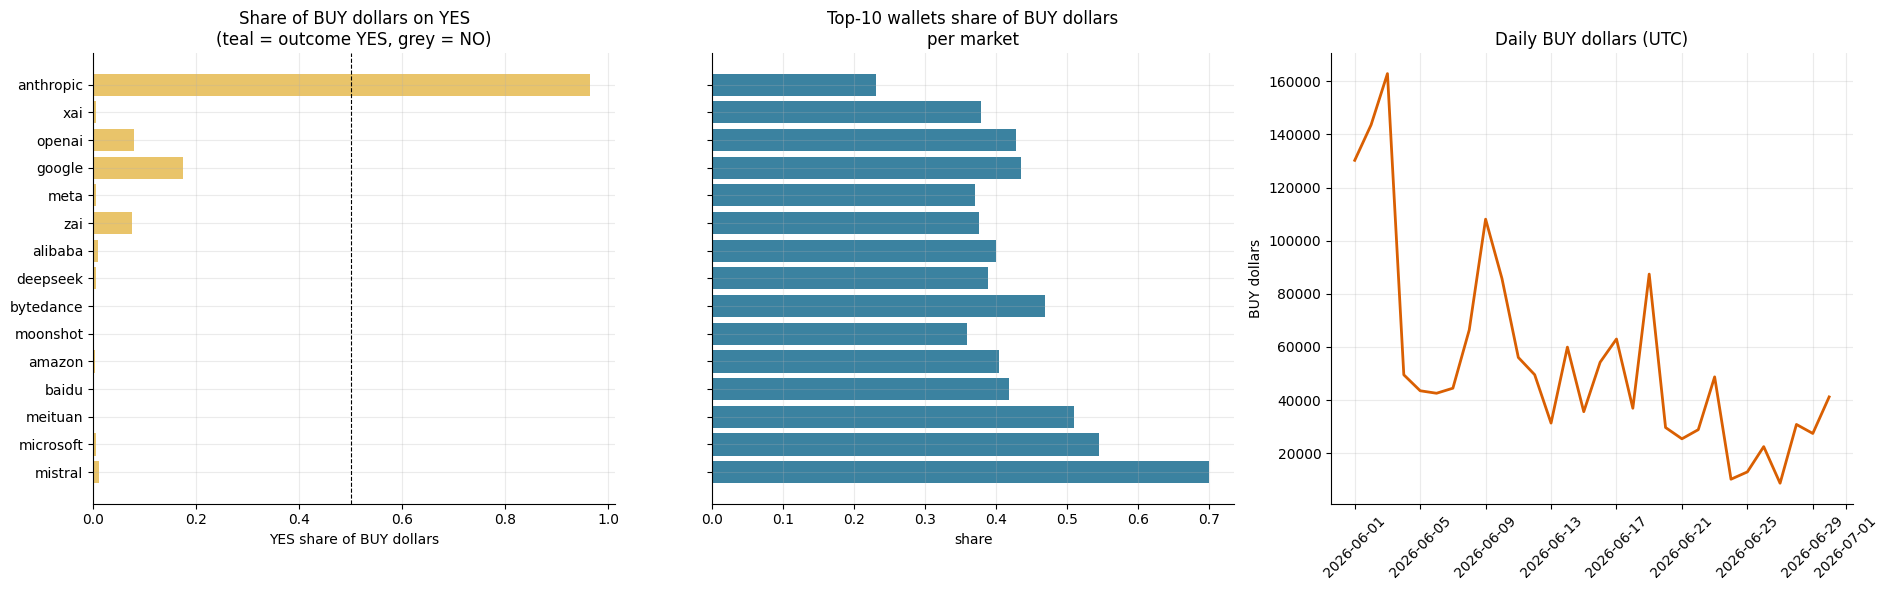

In [13]:
# Market-level profile: direction of money, concentration among the top wallets, and daily volume
import matplotlib.pyplot as plt

mk = (pos.groupby('market')
         .agg(wallets=('wallet', 'nunique'),
              buy_dollars=('buy_dollars', 'sum'),
              yes_dollars=('side_dollars', lambda s: s[pos.loc[s.index, 'direction'].eq('YES')].sum()))
         .reset_index())
mk['yes_share'] = mk['yes_dollars'] / mk['buy_dollars']
top10 = (pos.sort_values('buy_dollars', ascending=False).groupby('market').head(10)
            .groupby('market')['buy_dollars'].sum().rename('top10_dollars').reset_index())
mk = (mk.merge(top10, on='market')
        .merge(outcome[['market', 'short', 'yes_outcome']], on='market'))
mk['top10_wallet_share'] = mk['top10_dollars'] / mk['buy_dollars']
mk = mk.sort_values('buy_dollars')
display(mk[['short', 'wallets', 'buy_dollars', 'yes_share', 'top10_wallet_share', 'yes_outcome']].round(3))

daily = (trades.loc[trades['trade_side'].eq('BUY')]
         .assign(day=lambda d: d['timestamp'].dt.tz_convert('UTC').dt.floor('D'))
         .groupby('day')['notional'].sum())

COLOR_YES = '#2A9D8F'
COLOR_NO = '#9AA5B1'
COLOR_UNKNOWN = '#E9C46A'
color_map = {1.0: COLOR_YES, 0.0: COLOR_NO}
colors = mk['yes_outcome'].map(color_map).fillna(COLOR_UNKNOWN)

fig, axes = plt.subplots(1, 3, figsize=(19, 6))
axes[0].barh(mk['short'], mk['yes_share'], color=colors)
axes[0].axvline(0.5, color='k', lw=0.8, ls='--')
axes[0].set_title('Share of BUY dollars on YES\n(teal = outcome YES, grey = NO)')
axes[0].set_xlabel('YES share of BUY dollars')
axes[1].barh(mk['short'], mk['top10_wallet_share'], color='#3B82A0')
axes[1].set_title('Top-10 wallets share of BUY dollars\nper market')
axes[1].set_xlabel('share')
axes[1].set_yticklabels([])
axes[2].plot(daily.index, daily.values, color='#D95F02', lw=2)
axes[2].set_title('Daily BUY dollars (UTC)')
axes[2].set_ylabel('BUY dollars')
axes[2].tick_params(axis='x', rotation=45)
for ax in axes:
    ax.grid(alpha=0.25)
    ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURE_DIR / '04_market_profile.png', dpi=220, bbox_inches='tight')
plt.show()
mk.to_csv(DATASET_DIR / 'market_profile.csv', index=False)

,price bin,positions,markets,BUY dollars,avg price paid,win rate,excess win,CI low,CI high
0,all positions,11499,15,1637681.342,0.864,0.894,0.029,0.001,0.045
1,"(-0.001, 0.1]",919,15,37012.547,0.028,0.000,-0.028,-0.040,-0.002
2,"(0.1, 0.3]",304,2,18564.593,0.145,0.000,-0.145,-0.154,-0.136
3,"(0.3, 0.5]",1,1,5229.050,0.305,0.000,-0.305,-0.305,-0.305
4,"(0.7, 0.9]",1624,2,217381.860,0.854,1.000,0.146,0.125,0.148
5,"(0.9, 0.99]",3237,3,463467.531,0.953,1.000,0.047,0.030,0.055
6,"(0.99, 1.0]",5414,15,896025.761,0.997,1.000,0.003,0.001,0.005


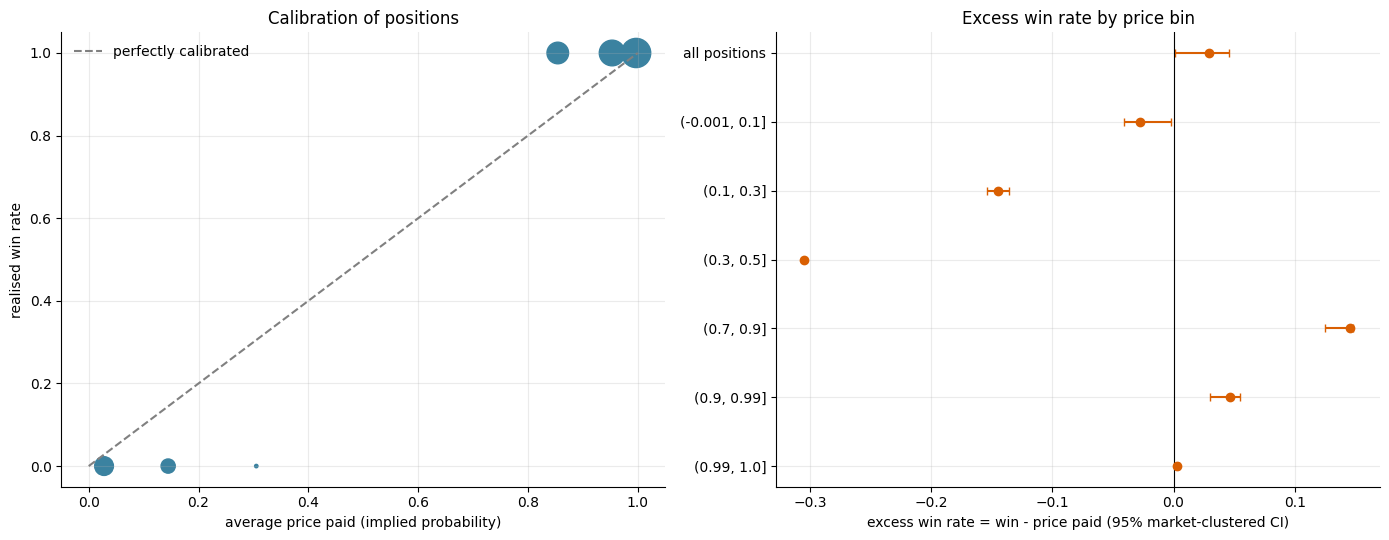

In [14]:
# Calibration check: does a wallet win more often than the price it paid?
# CI is a bootstrap that resamples whole markets (positions in one market are correlated).
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def cluster_boot_mean(df, col, cluster='market', n_boot=2000, seed=RANDOM_STATE):
    g = df.groupby(cluster)[col].agg(['sum', 'count'])
    s = g['sum'].to_numpy()
    c = g['count'].to_numpy()
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(g), size=(n_boot, len(g)))
    boot = s[idx].sum(axis=1) / c[idx].sum(axis=1)
    return s.sum() / c.sum(), np.percentile(boot, 2.5), np.percentile(boot, 97.5)

ev = pos.dropna(subset=['win']).copy()
bins = [0, .1, .3, .5, .7, .9, .99, 1.0]
ev['price_bin'] = pd.cut(ev['side_price'], bins, include_lowest=True)

groups = [('all positions', ev)]
groups += [(str(k), v) for k, v in ev.groupby('price_bin', observed=True)]

rows = []
for name, d in groups:
    m, lo, hi = cluster_boot_mean(d, 'excess')
    rows.append({
        'price bin': name,
        'positions': len(d),
        'markets': d['market'].nunique(),
        'BUY dollars': d['buy_dollars'].sum(),
        'avg price paid': d['side_price'].mean(),
        'win rate': d['win'].mean(),
        'excess win': m,
        'CI low': lo,
        'CI high': hi,
    })
calib = pd.DataFrame(rows)
display(calib.round(3))

plot = calib.iloc[1:]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
axes[0].plot([0, 1], [0, 1], '--', color='gray', label='perfectly calibrated')
axes[0].scatter(plot['avg price paid'], plot['win rate'],
                s=np.sqrt(plot['positions']) * 6, color='#3B82A0')
axes[0].set_xlabel('average price paid (implied probability)')
axes[0].set_ylabel('realised win rate')
axes[0].set_title('Calibration of positions')
axes[0].legend(frameon=False)

y = np.arange(len(calib))[::-1]
err_low = calib['excess win'] - calib['CI low']
err_high = calib['CI high'] - calib['excess win']
axes[1].errorbar(calib['excess win'], y, xerr=[err_low, err_high],
                 fmt='o', color='#D95F02', capsize=3)
axes[1].axvline(0, color='k', lw=0.8)
axes[1].set_yticks(y)
axes[1].set_yticklabels(calib['price bin'])
axes[1].set_xlabel('excess win rate = win - price paid (95% market-clustered CI)')
axes[1].set_title('Excess win rate by price bin')
for ax in axes:
    ax.grid(alpha=0.25)
    ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURE_DIR / '15_calibration_excess_win.png', dpi=220, bbox_inches='tight')
plt.show()
calib.to_csv(DATASET_DIR / 'calibration_excess_win.csv', index=False)

## 5. Behavioural wallet profiling

This section switches to wallet-level behavioural features, as another main experimental design for the AI-model event. This section uses six new wallet-level features and no longer depends on the old features removed earlier.

The goal is to identify behaviors such as unusually large orders, high market impact, concentrated capital, new wallets, and coverage of few markets. A high score indicates unusual behaviour; it does not prove insider trading.

In [15]:
# Construct the six alternative wallet-level features
import numpy as np
import pandas as pd

buy = trades.loc[trades['trade_side'].eq('BUY')].copy()
buy['notional'] = pd.to_numeric(buy['notional'], errors='coerce')
buy['price'] = pd.to_numeric(buy['price'], errors='coerce')
buy = buy.dropna(subset=['wallet','market','timestamp','notional','price'])
buy = buy[buy['notional'] > 0].copy()

wm_beh = (buy.groupby(['wallet','market'], as_index=False)
          .agg(market_buy_dollars=('notional','sum'),
               n_market_trades=('notional','size')))
price_num = (buy.assign(price_num=buy['price'] * buy['notional'])
             .groupby(['wallet','market'], as_index=False)['price_num'].sum())
wm_beh = wm_beh.merge(price_num, on=['wallet','market'], how='left')
wm_beh['market_avg_buy_price'] = wm_beh['price_num'] / wm_beh['market_buy_dollars']

wallet_totals = (wm_beh.groupby('wallet', as_index=False)
                 .agg(total_buy_dollars=('market_buy_dollars','sum'),
                      unique_markets=('market','nunique')))
market_totals_beh = (wm_beh.groupby('market', as_index=False)
                     .agg(market_total_buy_dollars=('market_buy_dollars','sum')))
wm_beh = wm_beh.merge(wallet_totals, on='wallet').merge(market_totals_beh, on='market')

wm_beh['market_notional_ratio'] = (
    wm_beh['market_buy_dollars'] / wm_beh['market_total_buy_dollars'].replace(0, np.nan)
)
wm_beh['wallet_market_share'] = (
    wm_beh['market_buy_dollars'] / wm_beh['total_buy_dollars'].replace(0, np.nan)
)
wallet_features_beh = (wm_beh.groupby('wallet')
    .agg(total_buy_dollars=('total_buy_dollars','first'),
         unique_markets=('unique_markets','first'),
         avg_spend_per_market=('market_buy_dollars','mean'),
         market_notional_ratio=('market_notional_ratio','max'),
         avg_buy_price=('market_avg_buy_price',
                        lambda x: np.average(x, weights=wm_beh.loc[x.index,'market_buy_dollars'])),
         concentration=('wallet_market_share','max'))
    .reset_index())

largest_single_buy = buy.groupby('wallet')['notional'].max().rename('largest_single_buy')
wallet_features_beh = wallet_features_beh.merge(largest_single_buy, on='wallet', how='left')
wallet_features_beh['position_anomaly_ratio'] = (
    wallet_features_beh['largest_single_buy'] /
    wallet_features_beh['avg_spend_per_market'].replace(0, np.nan)
)

first_last = (buy.groupby('wallet')['timestamp'].agg(first_trade='min', last_trade='max').reset_index())
wallet_features_beh = wallet_features_beh.merge(first_last, on='wallet', how='left')
wallet_features_beh['wallet_age_days'] = (
    wallet_features_beh['last_trade'] - wallet_features_beh['first_trade']
).dt.total_seconds() / 86400
wallet_features_beh['wallet_age_days'] = wallet_features_beh['wallet_age_days'].clip(lower=0)

if 'win' in wm.columns:
    wallet_features_beh = wallet_features_beh.merge(
        wm.groupby('wallet')['win'].mean().rename('win_rate'),
        on='wallet', how='left'
    )

behaviour_cols = ['position_anomaly_ratio','market_notional_ratio','avg_buy_price',
                  'concentration','wallet_age_days','unique_markets']
wallet_features_beh[behaviour_cols] = wallet_features_beh[behaviour_cols].replace(
    [np.inf,-np.inf], np.nan
)
wallet_features_beh = wallet_features_beh.dropna(subset=behaviour_cols).reset_index(drop=True)
display(wallet_features_beh.head())
print('wallet behavioural profiles:', wallet_features_beh.shape)

,wallet,total_buy_dollars,unique_markets,avg_spend_per_market,market_notional_ratio,avg_buy_price,concentration,largest_single_buy,position_anomaly_ratio,first_trade,last_trade,wallet_age_days,win_rate
0,0x0008d433ab85728f20d8da57bfff5187feccfbd7,10.879998,1,10.879998,0.000019,0.994000,1.0,10.879998,1.0,2026-06-29 03:23:50+00:00,2026-06-29 03:23:50+00:00,0.0,1.0
1,0x000dd715ae1dc4a7d25b18bbcc1eaae1dc82fb41,0.999998,1,0.999998,0.000002,0.984999,1.0,0.999998,1.0,2026-06-25 06:20:25+00:00,2026-06-25 06:20:25+00:00,0.0,1.0
2,0x00106a662bbacdfc181885124f6c764c18ab8daa,10.879998,1,10.879998,0.000019,0.994000,1.0,10.879998,1.0,2026-06-29 02:29:05+00:00,2026-06-29 02:29:05+00:00,0.0,1.0
3,0x001139c7df18cc8c07713873df723445e1899c78,1.999999,1,1.999999,0.000016,0.052000,1.0,1.999999,1.0,2026-06-23 02:43:52+00:00,2026-06-23 02:43:52+00:00,0.0,0.0
4,0x001a75418f37750d65eb7abe44c4f845ffa333ed,1.999998,1,1.999998,0.000004,0.989000,1.0,1.999998,1.0,2026-06-24 02:45:58+00:00,2026-06-24 02:45:58+00:00,0.0,1.0


wallet behavioural profiles: (9467, 13)


In [16]:
# Log-transform the heavy-tailed market share, then standardise all six features, then Isolation Forest
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest

wallet_features_beh['log_position_anomaly_ratio'] = np.log1p(
    wallet_features_beh['position_anomaly_ratio'].clip(lower=0))
wallet_features_beh['log_wallet_age_days'] = np.log1p(
    wallet_features_beh['wallet_age_days'].clip(lower=0))
wallet_features_beh['log_unique_markets'] = np.log1p(
    wallet_features_beh['unique_markets'].clip(lower=0))
# market share spans 1e-5 to 0.37, so a raw scaler lets a few wallets dominate every model
wallet_features_beh['log_market_notional_ratio'] = np.log10(
    wallet_features_beh['market_notional_ratio'].clip(lower=1e-6))

model_beh_cols = ['log_position_anomaly_ratio', 'log_market_notional_ratio', 'avg_buy_price',
                  'concentration', 'log_wallet_age_days', 'log_unique_markets']
beh_scaler = StandardScaler()
X_beh = beh_scaler.fit_transform(wallet_features_beh[model_beh_cols])
print('max |z| per feature:', dict(zip(model_beh_cols, np.abs(X_beh).max(axis=0).round(1))))

beh_iso = IsolationForest(n_estimators=300, contamination=0.05, random_state=RANDOM_STATE)
beh_iso.fit(X_beh)
wallet_features_beh['behavioural_anomaly_score'] = -beh_iso.decision_function(X_beh)
wallet_features_beh['behavioural_anomaly_percentile'] = (
    wallet_features_beh['behavioural_anomaly_score'].rank(pct=True))
wallet_features_beh['behavioural_anomaly'] = (
    wallet_features_beh['behavioural_anomaly_percentile'] >= 0.95)

display(wallet_features_beh.sort_values('behavioural_anomaly_score', ascending=False).head(20))

max |z| per feature: {'log_position_anomaly_ratio': np.float64(8.9), 'log_market_notional_ratio': np.float64(3.8), 'avg_buy_price': np.float64(3.4), 'concentration': np.float64(6.0), 'log_wallet_age_days': np.float64(4.4), 'log_unique_markets': np.float64(9.1)}


,wallet,total_buy_dollars,unique_markets,avg_spend_per_market,market_notional_ratio,avg_buy_price,concentration,largest_single_buy,position_anomaly_ratio,first_trade,last_trade,wallet_age_days,win_rate,log_position_anomaly_ratio,log_wallet_age_days,log_unique_markets,log_market_notional_ratio,behavioural_anomaly_score,behavioural_anomaly_percentile,behavioural_anomaly
8466,0xe5eb0915873ab76fe78c960ed340f72a91dd7e3d,35328.508870,15,2355.233925,0.102606,0.978931,0.078011,108.411480,0.046030,2026-06-01 09:36:59+00:00,2026-06-26 19:23:05+00:00,25.407014,0.933333,0.045002,3.273630,2.772589,-0.988827,0.162296,1.000000,True
6704,0xb4b5bf2c0c1993b1346b307010e49336719c7524,19499.038000,15,1299.935867,0.057426,0.988460,0.111942,124.875000,0.096062,2026-06-01 00:53:14+00:00,2026-06-23 11:05:13+00:00,22.424988,0.933333,0.091724,3.153803,2.772589,-1.240891,0.161224,0.999894,True
1557,0x291f6a4f9ad3796fd0adaa0b2a5ac9922422e7eb,48341.501080,14,3452.964363,0.070641,0.982943,0.149336,55.944000,0.016202,2026-06-01 00:21:20+00:00,2026-06-27 00:25:28+00:00,26.002870,0.928571,0.016072,3.295943,2.708050,-1.150941,0.161047,0.999736,True
7159,0xc1dad45dc14d9dc175ef2b1c2e6496d5f48e778a,17915.259990,15,1194.350666,0.043297,0.984882,0.106418,94.905000,0.079462,2026-06-01 08:23:15+00:00,2026-06-23 08:09:55+00:00,21.990741,0.933333,0.076462,3.135092,2.772589,-1.363538,0.161047,0.999736,True
6049,0xa322ab1cc518d97a1c8fe587f1fc445c68032d2c,45050.685090,14,3217.906078,0.059467,0.986038,0.127016,160.389450,0.049843,2026-06-01 10:22:10+00:00,2026-06-23 09:06:55+00:00,21.947743,1.000000,0.048640,3.133220,2.708050,-1.225721,0.159282,0.999577,True
5558,0x9528c137aebe01fb5273ee9fab7b0b2bc3eed26b,22749.053110,15,1516.603541,0.054159,0.986451,0.085506,149.850000,0.098806,2026-06-01 00:53:37+00:00,2026-06-19 13:42:10+00:00,18.533715,0.933333,0.094224,2.972142,2.772589,-1.266332,0.159106,0.999472,True
2647,0x4582e2e1bf94b8d620053c426208ed3e40201b30,55334.938316,15,3688.995888,0.104143,0.981643,0.145164,1048.499451,0.284224,2026-06-01 00:21:20+00:00,2026-06-27 00:25:28+00:00,26.002870,0.933333,0.250154,3.295943,2.772589,-0.982371,0.158588,0.999366,True
6195,0xa7cadea7e81e625ba836fe33d4f3849fcde5414e,16274.515000,15,1084.967667,0.043629,0.993891,0.153918,124.875000,0.115096,2026-06-01 00:53:14+00:00,2026-06-19 19:45:05+00:00,18.786007,0.933333,0.108940,2.984975,2.772589,-1.360226,0.158049,0.999261,True
23,0x00a5811e8e554f5cc3954e4c5cbac57b3b9442d6,57187.774360,15,3812.518291,0.115073,0.977918,0.258299,364.635000,0.095642,2026-06-03 03:04:09+00:00,2026-06-27 00:37:53+00:00,23.898426,0.933333,0.091340,3.214805,2.772589,-0.939025,0.156441,0.999155,True
3300,0x575578d1031feab216ecc7ce4f1d9aea7cc823ba,6668.847160,15,444.589811,0.017527,0.984317,0.104346,99.900000,0.224702,2026-06-01 14:01:23+00:00,2026-06-23 06:36:46+00:00,21.691238,0.933333,0.202697,3.121979,2.772589,-1.756301,0.152437,0.999049,True


In [17]:
# Transparent rule-based score for PPT interpretation
rule_features = {
    'large_position_flag': wallet_features_beh['position_anomaly_ratio'] >= wallet_features_beh['position_anomaly_ratio'].quantile(.95),
    'market_impact_flag': wallet_features_beh['market_notional_ratio'] >= .10,
    'conviction_flag': wallet_features_beh['avg_buy_price'].between(.20,.80),
    'concentrated_flag': wallet_features_beh['concentration'] >= .80,
    'new_wallet_flag': wallet_features_beh['wallet_age_days'] <= 7,
    'focused_market_flag': wallet_features_beh['unique_markets'] <= 2,
}
for name, values in rule_features.items():
    wallet_features_beh[name] = values.astype(int)
rule_cols = list(rule_features)
wallet_features_beh['behavioural_risk_score'] = wallet_features_beh[rule_cols].sum(axis=1)

display(wallet_features_beh[rule_cols + ['behavioural_risk_score']].sum()
        .sort_values(ascending=False).to_frame('count'))
display(wallet_features_beh.sort_values(
    ['behavioural_risk_score','behavioural_anomaly_score'], ascending=False).head(20))


,count
behavioural_risk_score,27161
focused_market_flag,9124
new_wallet_flag,8847
concentrated_flag,8595
large_position_flag,474
conviction_flag,117
market_impact_flag,4


,wallet,total_buy_dollars,unique_markets,avg_spend_per_market,market_notional_ratio,avg_buy_price,concentration,largest_single_buy,position_anomaly_ratio,first_trade,last_trade,wallet_age_days,win_rate,log_position_anomaly_ratio,log_wallet_age_days,log_unique_markets,log_market_notional_ratio,behavioural_anomaly_score,behavioural_anomaly_percentile,behavioural_anomaly,large_position_flag,market_impact_flag,conviction_flag,concentrated_flag,new_wallet_flag,focused_market_flag,behavioural_risk_score
9444,0xff381c20ca7ae8fbe1764ccb77b7ecfd5311bb06,165.774300,2,82.887150,0.001145,0.217724,0.874680,144.999400,1.749359,2026-06-06 05:27:58+00:00,2026-06-06 06:02:27+00:00,0.023947,0.5,1.011368,0.023665,1.098612,-2.941349,0.047720,0.980036,True,1,0,1,1,1,1,5
2193,0x39e95880abbdf51369530db53553aa39f06aef1d,26.974000,2,13.487000,0.000044,0.785630,0.933121,25.170000,1.866242,2026-06-07 07:11:25+00:00,2026-06-10 23:59:49+00:00,3.700278,0.5,1.053002,1.547622,1.098612,-4.352634,0.027049,0.970635,True,1,0,1,1,1,1,5
5969,0xa13ac2008c564c55a8033ed8720a092dcd7c1b1e,226.334932,2,113.167466,0.000320,0.727611,0.800849,181.259993,1.601697,2026-06-14 19:54:00+00:00,2026-06-18 06:46:46+00:00,3.453310,0.5,0.956164,1.493648,1.098612,-3.495215,0.013442,0.961868,True,1,0,1,1,1,1,5
7221,0xc3a33bdcaebbcdec8c993e74c7c7906c686722e2,19.999997,2,9.999999,0.000030,0.733720,0.860000,17.199998,1.720000,2026-06-06 13:48:27+00:00,2026-06-06 13:48:27+00:00,0.000000,0.5,1.000632,0.000000,1.098612,-4.517989,-0.012005,0.936622,False,1,0,1,1,1,1,5
3132,0x52ea44734716e5684205bf75e204e705db82d6d6,7.999992,2,3.999996,0.000055,0.799875,0.875000,6.999993,1.750000,2026-06-12 15:27:28+00:00,2026-06-12 15:27:33+00:00,0.000058,0.5,1.011601,0.000058,1.098612,-4.257618,-0.013501,0.935143,False,1,0,1,1,1,1,5
2367,0x3edb59d040f5c0fabbcee69426a8bbab87cb25f6,295.521670,2,147.760835,0.002289,0.137440,0.981231,289.975000,1.962462,2026-06-03 13:45:38+00:00,2026-06-09 01:56:54+00:00,5.507824,0.0,1.086021,1.873005,1.098612,-2.640355,0.074751,0.989120,True,1,0,0,1,1,1,4
3488,0x5bcf9351b2d63aa4b5579417014c53619dfc35f9,7.000000,2,3.500000,0.000048,0.001857,0.857143,6.000000,1.714286,2026-06-17 00:54:05+00:00,2026-06-20 03:46:43+00:00,3.119884,0.0,0.998529,1.415825,1.098612,-4.319797,0.062916,0.986268,True,1,0,0,1,1,1,4
4540,0x79331f55ba6eca2255c4ae438d62ec215f564f33,10.999999,2,5.499999,0.000041,0.088637,0.909091,9.999999,1.818182,2026-06-10 21:19:40+00:00,2026-06-15 08:28:36+00:00,4.464537,0.0,1.036092,1.698279,1.098612,-4.382220,0.059690,0.985001,True,1,0,0,1,1,1,4
2562,0x4366ca05ce6eeaf10173f127b989fee624e150b9,50.028800,2,25.014400,0.000339,0.039769,0.859505,43.000000,1.719010,2026-06-20 06:45:28+00:00,2026-06-22 13:45:50+00:00,2.291921,0.0,1.000268,1.191471,1.098612,-3.469247,0.057634,0.983839,True,1,0,0,1,1,1,4
5225,0x8bab5676cc7a9d4d60f1a036eac62dbbfc399695,45.308990,2,22.654495,0.000316,0.036677,0.882827,40.000000,1.765654,2026-06-22 12:03:41+00:00,2026-06-23 12:52:40+00:00,1.034016,0.0,1.017277,0.710012,1.098612,-3.500655,0.052670,0.981620,True,1,0,0,1,1,1,4


In [18]:
# Wallet segmentation using only the six behavioural features
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
import seaborn as sns
import matplotlib.pyplot as plt

beh_cluster_results = []
for k_candidate in range(3, 7):
    labels = KMeans(n_clusters=k_candidate, n_init=30,
                    random_state=RANDOM_STATE).fit_predict(X_beh)
    beh_cluster_results.append({
        'k': k_candidate,
        'silhouette_score': silhouette_score(X_beh, labels)
    })
beh_cluster_results = pd.DataFrame(beh_cluster_results)
display(beh_cluster_results)

beh_k = int(beh_cluster_results.loc[
    beh_cluster_results['silhouette_score'].idxmax(), 'k'])
beh_kmeans = KMeans(n_clusters=beh_k, n_init=30, random_state=RANDOM_STATE)
wallet_features_beh['behaviour_cluster'] = beh_kmeans.fit_predict(X_beh)

beh_segment_summary = (wallet_features_beh.groupby('behaviour_cluster')
    .agg(n_wallets=('wallet','size'),
         median_position_anomaly=('position_anomaly_ratio','median'),
         median_market_impact=('market_notional_ratio','median'),
         median_avg_price=('avg_buy_price','median'),
         median_concentration=('concentration','median'),
         median_wallet_age=('wallet_age_days','median'),
         median_unique_markets=('unique_markets','median'),
         mean_risk_score=('behavioural_risk_score','mean'),
         win_rate=('win_rate','mean') if 'win_rate' in wallet_features_beh
         else ('wallet','size'))
    .reset_index())
beh_segment_summary['wallet_share'] = (
    beh_segment_summary['n_wallets'] / len(wallet_features_beh))
display(beh_segment_summary.sort_values('mean_risk_score', ascending=False))


/Users/zhongyangfan/Desktop/L3_prediction_markets_student_package_2026-10-07/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/zhongyangfan/Desktop/L3_prediction_markets_student_package_2026-10-07/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/zhongyangfan/Desktop/L3_prediction_markets_student_package_2026-10-07/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/zhongyangfan/Desktop/L3_prediction_markets_student_package_2026-10-07/.venv/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/zhongyangfan/Desktop/L3_prediction_markets_student_package_2026-10-07/.venv/lib/python3.10/site-packages/sklearn/cluster/_kmeans

,k,silhouette_score
0,3,0.56606
1,4,0.56451
2,5,0.47028
3,6,0.48374


/Users/zhongyangfan/Desktop/L3_prediction_markets_student_package_2026-10-07/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/zhongyangfan/Desktop/L3_prediction_markets_student_package_2026-10-07/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/zhongyangfan/Desktop/L3_prediction_markets_student_package_2026-10-07/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/zhongyangfan/Desktop/L3_prediction_markets_student_package_2026-10-07/.venv/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/zhongyangfan/Desktop/L3_prediction_markets_student_package_2026-10-07/.venv/lib/python3.10/site-packages/sklearn/cluster/_kmeans

,behaviour_cluster,n_wallets,median_position_anomaly,median_market_impact,median_avg_price,median_concentration,median_wallet_age,median_unique_markets,mean_risk_score,win_rate,wallet_share
0,0,7822,1.000000,0.000051,0.991000,1.000000,0.000000,1.0,2.987216,0.999361,0.826239
2,2,771,1.000000,0.000027,0.042444,1.000000,0.000000,1.0,2.961089,0.007134,0.081441
1,1,874,1.008341,0.000441,0.961469,0.526803,5.959462,2.0,1.729977,0.892937,0.092321


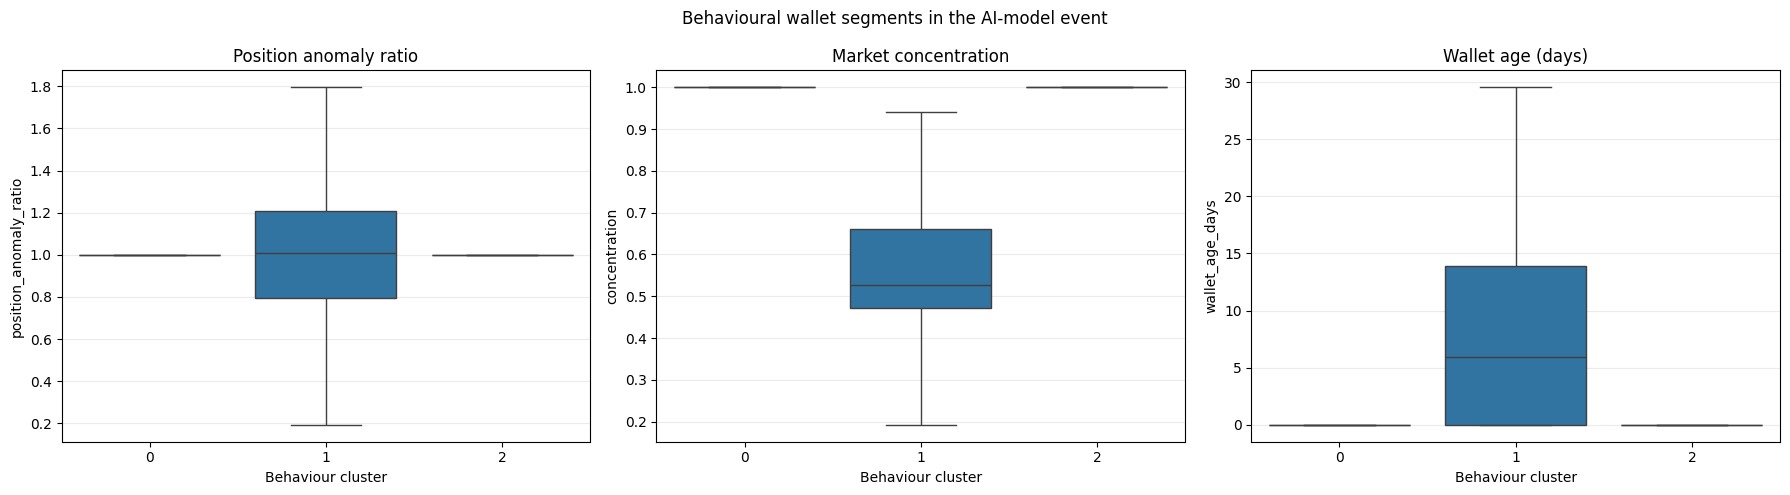

/Users/zhongyangfan/Desktop/L3_prediction_markets_student_package_2026-10-07/.venv/lib/python3.10/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: divide by zero encountered in matmul
  X_transformed = X @ self.components_.T
/Users/zhongyangfan/Desktop/L3_prediction_markets_student_package_2026-10-07/.venv/lib/python3.10/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: overflow encountered in matmul
  X_transformed = X @ self.components_.T
/Users/zhongyangfan/Desktop/L3_prediction_markets_student_package_2026-10-07/.venv/lib/python3.10/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: invalid value encountered in matmul
  X_transformed = X @ self.components_.T


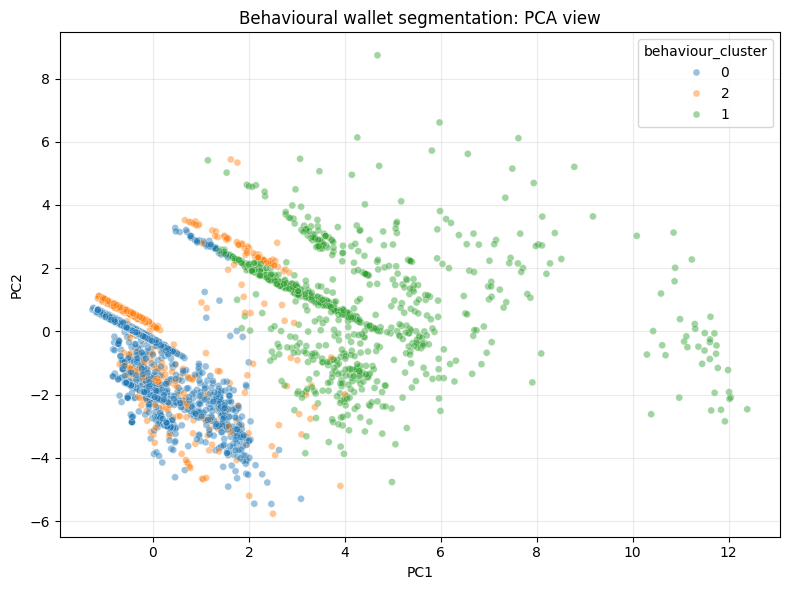

In [19]:
# Behavioural segment comparison and PCA visualisation
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

FIGURE_DIR.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.boxplot(data=wallet_features_beh, x='behaviour_cluster',
            y='position_anomaly_ratio', showfliers=False, ax=axes[0])
axes[0].set_title('Position anomaly ratio')
sns.boxplot(data=wallet_features_beh, x='behaviour_cluster',
            y='concentration', showfliers=False, ax=axes[1])
axes[1].set_title('Market concentration')
sns.boxplot(data=wallet_features_beh, x='behaviour_cluster',
            y='wallet_age_days', showfliers=False, ax=axes[2])
axes[2].set_title('Wallet age (days)')
for ax in axes:
    ax.set_xlabel('Behaviour cluster')
    ax.grid(axis='y', alpha=.25)
fig.suptitle('Behavioural wallet segments in the AI-model event')
fig.tight_layout()
fig.savefig(FIGURE_DIR / '12_behavioural_segment_features.png', dpi=220, bbox_inches='tight')
plt.show()

beh_pca = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X_beh)
fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(x=beh_pca[:, 0], y=beh_pca[:, 1],
                hue=wallet_features_beh['behaviour_cluster'].astype(str),
                alpha=.45, s=25, palette='tab10', ax=ax)
ax.set_title('Behavioural wallet segmentation: PCA view')
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.grid(alpha=.25)
fig.tight_layout()
fig.savefig(FIGURE_DIR / '13_behavioural_segmentation_pca.png', dpi=220, bbox_inches='tight')
plt.show()

,position_anomaly_ratio,market_notional_ratio,avg_buy_price,concentration,wallet_age_days,unique_markets
position_anomaly_ratio,1.000,-0.070,0.020,-0.095,-0.192,0.020
market_notional_ratio,-0.070,1.000,0.043,-0.204,0.242,0.417
avg_buy_price,0.020,0.043,1.000,0.064,-0.032,-0.032
concentration,-0.095,-0.204,0.064,1.000,-0.490,-0.732
wallet_age_days,-0.192,0.242,-0.032,-0.490,1.000,0.564
unique_markets,0.020,0.417,-0.032,-0.732,0.564,1.000


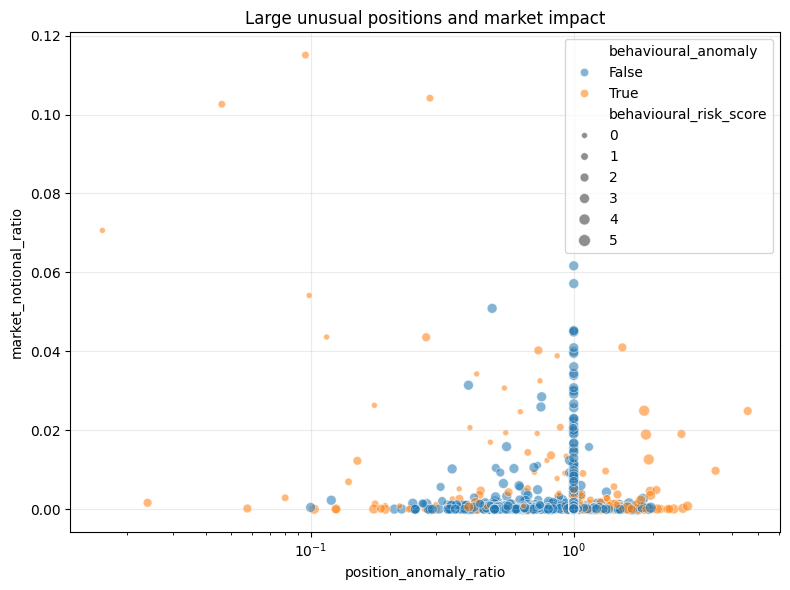

In [20]:
# Correlation and anomaly map for the new design
beh_corr_cols = ['position_anomaly_ratio','market_notional_ratio','avg_buy_price',
                 'concentration','wallet_age_days','unique_markets']
display(wallet_features_beh[beh_corr_cols].corr().round(3))

fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(
    data=wallet_features_beh.sample(min(5000,len(wallet_features_beh)),
                                     random_state=RANDOM_STATE),
    x='position_anomaly_ratio', y='market_notional_ratio',
    size='behavioural_risk_score', hue='behavioural_anomaly',
    alpha=.55, ax=ax)
ax.set_xscale('log')
ax.set_title('Large unusual positions and market impact')
ax.grid(alpha=.25)
fig.tight_layout()
fig.savefig(FIGURE_DIR / '14_behavioural_anomaly_map.png', dpi=220, bbox_inches='tight')
plt.show()


### Interpretation note

The new model identifies wallets that are unusual relative to the rest of this event. A high score can reflect a whale, a market maker, a concentrated bettor, a newly created wallet, or an informed trader. We compare segments using realized win rate and market share, but do not label any wallet as a confirmed insider without an external ground-truth label.

## 5B. Detector comparison and post-hoc evaluation

The same six behavioural features go through three unsupervised detectors (Isolation Forest, PCA reconstruction error, LOF).
We check agreement and stability, then whether flagged wallets win more than the price they paid. There are no insider
labels here, so this is a sanity check, not precision.

PCA explained variance (3 comps): [0.414 0.202 0.184] | total 0.799


/Users/zhongyangfan/Desktop/L3_prediction_markets_student_package_2026-10-07/.venv/lib/python3.10/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: divide by zero encountered in matmul
  X_transformed = X @ self.components_.T
/Users/zhongyangfan/Desktop/L3_prediction_markets_student_package_2026-10-07/.venv/lib/python3.10/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: overflow encountered in matmul
  X_transformed = X @ self.components_.T
/Users/zhongyangfan/Desktop/L3_prediction_markets_student_package_2026-10-07/.venv/lib/python3.10/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: invalid value encountered in matmul
  X_transformed = X @ self.components_.T
/Users/zhongyangfan/Desktop/L3_prediction_markets_student_package_2026-10-07/.venv/lib/python3.10/site-packages/sklearn/decomposition/_base.py:197: RuntimeWarning: divide by zero encountered in matmul
  return X @ self.components_ + self.mean_
/Users/zhongyangfan/Desktop/L3_predic

,Isolation Forest,PCA recon. error,LOF
Isolation Forest,1.000,0.708,0.198
PCA recon. error,0.708,1.000,0.173
LOF,0.198,0.173,1.000


,Isolation Forest,PCA recon. error,LOF
Isolation Forest,1.000,0.293,0.006
PCA recon. error,0.293,1.000,0.018
LOF,0.006,0.018,1.000


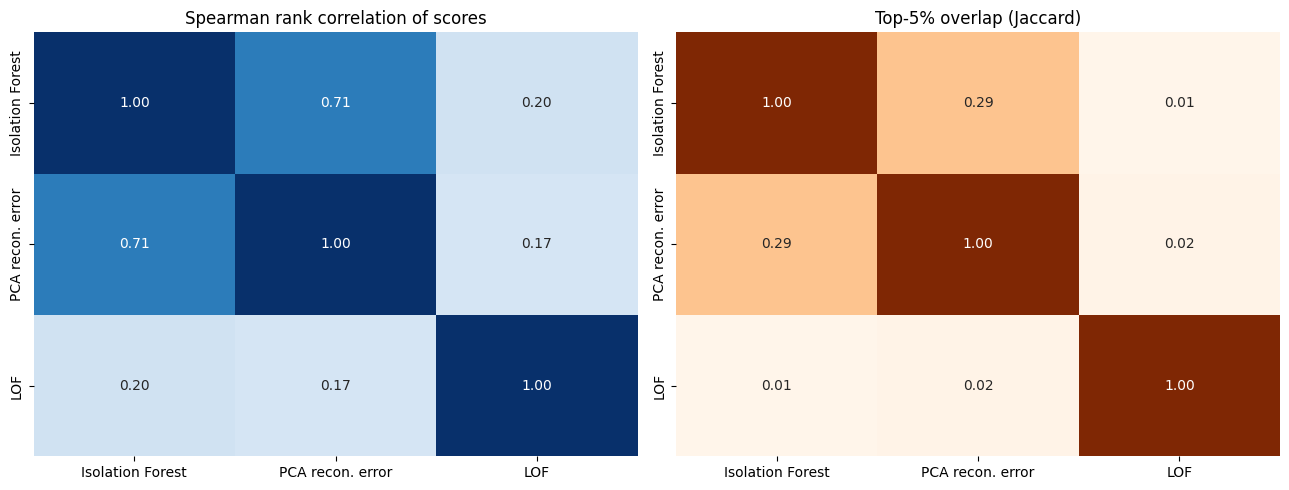

,seed,top5_jaccard_vs_reference
0,1,0.885
1,2,0.907
2,3,0.877
3,4,0.855
4,5,0.888


mean seed-to-reference Jaccard: 0.883


In [21]:
# Compare three unsupervised detectors on the same six behavioural features
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor

# PCA reconstruction error (distance from the principal subspace)
pca = PCA(n_components=3, random_state=RANDOM_STATE).fit(X_beh)
recon = pca.inverse_transform(pca.transform(X_beh))
wallet_features_beh['pca_recon_score'] = ((X_beh - recon) ** 2).sum(axis=1)
print('PCA explained variance (3 comps):', pca.explained_variance_ratio_.round(3),
      '| total', pca.explained_variance_ratio_.sum().round(3))

# Local Outlier Factor (density-based)
lof = LocalOutlierFactor(n_neighbors=35, contamination=0.05)
lof.fit(X_beh)
wallet_features_beh['lof_score'] = -lof.negative_outlier_factor_

score_cols = {
    'Isolation Forest': 'behavioural_anomaly_score',
    'PCA recon. error': 'pca_recon_score',
    'LOF': 'lof_score',
}
ranks = wallet_features_beh[list(score_cols.values())].rank(pct=True)
ranks.columns = list(score_cols)
wallet_features_beh['ensemble_score'] = ranks.mean(axis=1)
cut = wallet_features_beh['ensemble_score'].quantile(0.95)
wallet_features_beh['ensemble_top5'] = wallet_features_beh['ensemble_score'] >= cut

top5 = {k: ranks[k] >= 0.95 for k in ranks}
names = list(ranks)
jac = pd.DataFrame(
    [[(top5[a] & top5[b]).sum() / (top5[a] | top5[b]).sum() for b in names] for a in names],
    index=names, columns=names)
spear = ranks.corr(method='spearman')
display(spear.round(3))
display(jac.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(spear, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, ax=axes[0], cbar=False)
axes[0].set_title('Spearman rank correlation of scores')
sns.heatmap(jac, annot=True, fmt='.2f', cmap='Oranges', vmin=0, vmax=1, ax=axes[1], cbar=False)
axes[1].set_title('Top-5% overlap (Jaccard)')
fig.tight_layout()
fig.savefig(FIGURE_DIR / '16_detector_agreement.png', dpi=220, bbox_inches='tight')
plt.show()

# Stability of Isolation Forest across random seeds
# (top-5% overlap with the score computed in section 5)
base = wallet_features_beh['behavioural_anomaly_score']
ref = base >= base.quantile(0.95)
stab = []
for seed in range(1, 6):
    model = IsolationForest(n_estimators=300, contamination=0.05, random_state=seed).fit(X_beh)
    s = -model.decision_function(X_beh)
    t = s >= np.quantile(s, 0.95)
    stab.append({'seed': seed, 'top5_jaccard_vs_reference': (t & ref).sum() / (t | ref).sum()})
stab = pd.DataFrame(stab)
display(stab.round(3))
print('mean seed-to-reference Jaccard:', round(stab['top5_jaccard_vs_reference'].mean(), 3))

,group,wallets,positions,markets,BUY dollars,win rate,avg price paid,excess win,CI low,CI high
0,all positions,9467,11499,15,1637681.342,0.894,0.864,0.029,0.001,0.045
1,IF top 5%,474,1805,15,806138.254,0.684,0.687,-0.003,-0.007,0.001
2,IF top 1%,95,876,15,625695.703,0.776,0.779,-0.003,-0.013,0.003
3,PCA top 5%,474,1427,15,842747.278,0.767,0.764,0.003,-0.002,0.010
4,LOF top 5%,474,502,12,125132.966,0.936,0.916,0.020,0.001,0.023
5,Ensemble top 5%,474,1108,15,404343.099,0.636,0.631,0.006,-0.008,0.021
6,Everyone else (IF),8993,9694,15,831543.087,0.933,0.898,0.035,0.001,0.051


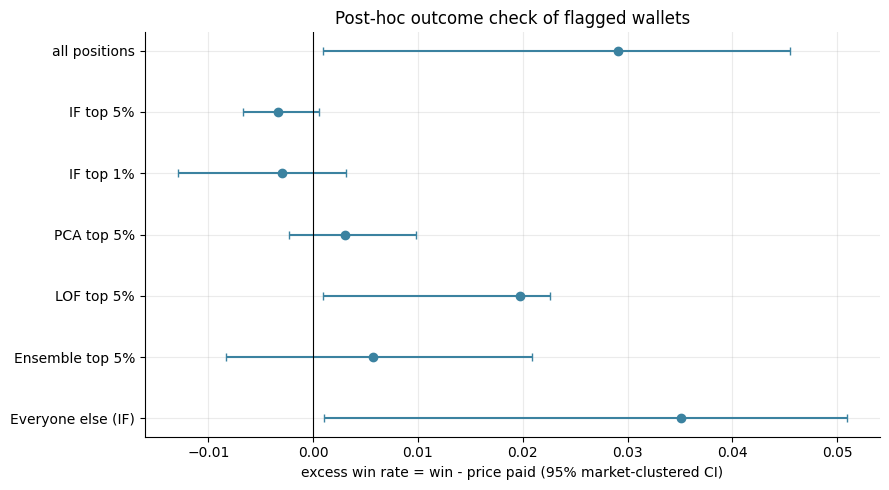

Caution: 1 YES market(s) among 15 markets in ONE event, so the number of independent outcomes is tiny. Read the CIs as exploratory.


In [22]:
# Do flagged wallets win more than the price they paid?
# Post-hoc check only; 95% CI is clustered by market.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

score_df = wallet_features_beh[['wallet', 'behavioural_anomaly_score', 'pca_recon_score',
                                'lof_score', 'ensemble_score']]
ev = pos.dropna(subset=['win']).merge(score_df, on='wallet', how='inner')

def top_mask(col, p):
    return ev[col] >= wallet_features_beh[col].quantile(p)

groups = {
    'all positions': ev['win'].notna(),
    'IF top 5%': top_mask('behavioural_anomaly_score', .95),
    'IF top 1%': top_mask('behavioural_anomaly_score', .99),
    'PCA top 5%': top_mask('pca_recon_score', .95),
    'LOF top 5%': top_mask('lof_score', .95),
    'Ensemble top 5%': top_mask('ensemble_score', .95),
    'Everyone else (IF)': ~top_mask('behavioural_anomaly_score', .95),
}

rows = []
for name, mask in groups.items():
    d = ev[mask]
    m, lo, hi = cluster_boot_mean(d, 'excess')
    rows.append({
        'group': name,
        'wallets': d['wallet'].nunique(),
        'positions': len(d),
        'markets': d['market'].nunique(),
        'BUY dollars': d['buy_dollars'].sum(),
        'win rate': d['win'].mean(),
        'avg price paid': d['side_price'].mean(),
        'excess win': m,
        'CI low': lo,
        'CI high': hi,
    })
eval_tbl = pd.DataFrame(rows)
display(eval_tbl.round(3))

fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(eval_tbl))[::-1]
err_low = eval_tbl['excess win'] - eval_tbl['CI low']
err_high = eval_tbl['CI high'] - eval_tbl['excess win']
ax.errorbar(eval_tbl['excess win'], y, xerr=[err_low, err_high],
            fmt='o', color='#3B82A0', capsize=3)
ax.axvline(0, color='k', lw=0.8)
ax.set_yticks(y)
ax.set_yticklabels(eval_tbl['group'])
ax.set_xlabel('excess win rate = win - price paid (95% market-clustered CI)')
ax.set_title('Post-hoc outcome check of flagged wallets')
ax.grid(alpha=0.25)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURE_DIR / '17_flagged_vs_rest_excess_win.png', dpi=220, bbox_inches='tight')
plt.show()
eval_tbl.to_csv(DATASET_DIR / 'flagged_vs_rest_excess_win.csv', index=False)

n_yes = int((outcome['yes_outcome'] == 1).sum())
print('Caution:', n_yes, 'YES market(s) among', len(outcome),
      'markets in ONE event, so the number of independent outcomes is tiny.',
      'Read the CIs as exploratory.')

,wallets,dollar_share,if_top5_rate,win_rate,wallet_share
behaviour_cluster,,,,,
0,7822,0.460,0.001,0.999,0.826
1,874,0.523,0.358,0.893,0.092
2,771,0.017,0.197,0.007,0.081


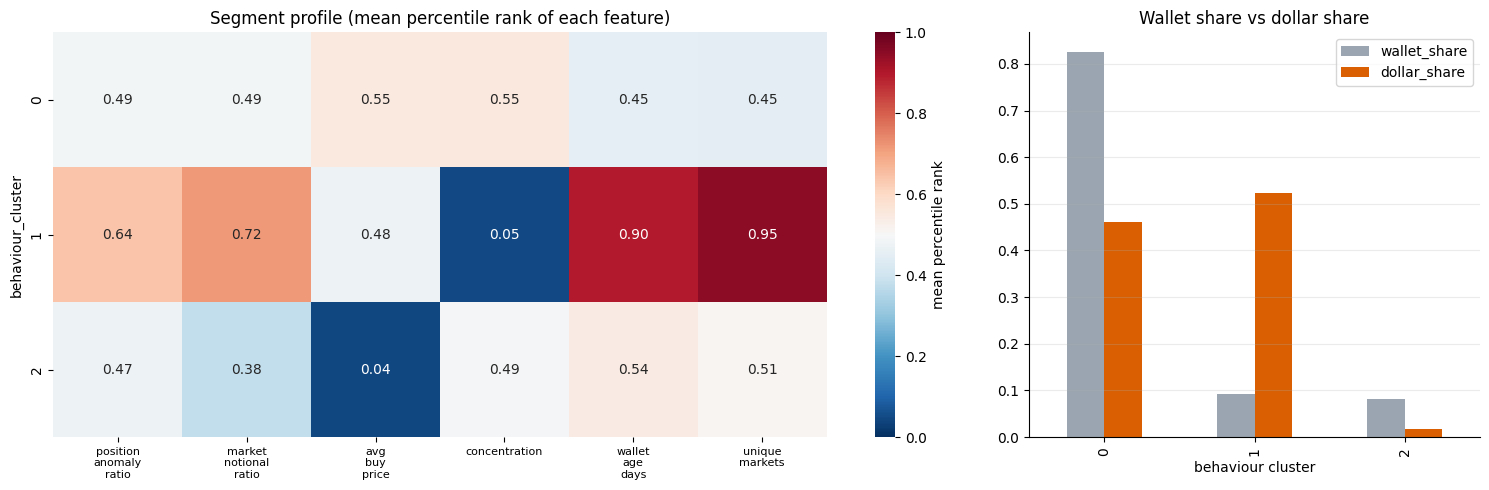

In [23]:
# Segment profile heatmap: what makes each behaviour cluster different, and how much money it controls
import seaborn as sns
import matplotlib.pyplot as plt

feat = ['position_anomaly_ratio', 'market_notional_ratio', 'avg_buy_price',
        'concentration', 'wallet_age_days', 'unique_markets']
pct = wallet_features_beh[feat].rank(pct=True)
pct['behaviour_cluster'] = wallet_features_beh['behaviour_cluster']
prof = pct.groupby('behaviour_cluster')[feat].mean()   # mean percentile rank of each feature

seg = (wallet_features_beh.groupby('behaviour_cluster')
       .agg(wallets=('wallet', 'size'),
            dollar_share=('total_buy_dollars', 'sum'),
            if_top5_rate=('behavioural_anomaly', 'mean'),
            win_rate=('win_rate', 'mean')))
seg['dollar_share'] = seg['dollar_share'] / seg['dollar_share'].sum()
seg['wallet_share'] = seg['wallets'] / seg['wallets'].sum()
display(seg.round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={'width_ratios': [3, 1.4]})
sns.heatmap(prof, annot=True, fmt='.2f', cmap='RdBu_r', center=0.5, vmin=0, vmax=1,
            ax=axes[0], cbar_kws={'label': 'mean percentile rank'})
axes[0].set_title('Segment profile (mean percentile rank of each feature)')
axes[0].set_xticklabels([f.replace('_', '\n') for f in feat], rotation=0, fontsize=8)
seg[['wallet_share', 'dollar_share']].plot.bar(ax=axes[1], color=['#9AA5B1', '#D95F02'])
axes[1].set_title('Wallet share vs dollar share')
axes[1].set_xlabel('behaviour cluster')
axes[1].grid(axis='y', alpha=0.25)
axes[1].spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURE_DIR / '18_segment_profile.png', dpi=220, bbox_inches='tight')
plt.show()
seg.to_csv(DATASET_DIR / 'segment_profile_extra.csv')

In [24]:
# Review list of the most unusual wallets + final summary table.
# No wallet is labelled an insider here; this is a screening list.
import numpy as np
import pandas as pd

top_cols = ['wallet', 'ensemble_score', 'behavioural_anomaly_score', 'pca_recon_score', 'lof_score',
            'position_anomaly_ratio', 'market_notional_ratio', 'concentration', 'wallet_age_days',
            'unique_markets', 'total_buy_dollars', 'win_rate', 'behaviour_cluster']
review = wallet_features_beh.sort_values('ensemble_score', ascending=False).head(20)[top_cols].copy()
review['wallet'] = review['wallet'].str[:6] + '...' + review['wallet'].str[-4:]
display(review.round(3))

flagged = wallet_features_beh['ensemble_top5']
dollar_share = (wallet_features_beh.loc[flagged, 'total_buy_dollars'].sum()
                / wallet_features_beh['total_buy_dollars'].sum())
mean_jaccard = float(jac.values[np.triu_indices(3, 1)].mean())

summary_rows = pd.DataFrame({
    'metric': ['wallets profiled',
               'ensemble top-5% wallets',
               'BUY-dollar share of ensemble top-5%',
               'IF/PCA/LOF mean pairwise Jaccard (top 5%)',
               'positions with outcome',
               'overall excess win rate'],
    'value': [len(wallet_features_beh),
              int(flagged.sum()),
              round(dollar_share, 3),
              round(mean_jaccard, 3),
              int(pos['win'].notna().sum()),
              round(float(pos['excess'].mean()), 4)],
})
display(summary_rows)

review.to_csv(DATASET_DIR / 'review_list_top20.csv', index=False)
summary_rows.to_csv(DATASET_DIR / 'insider_screening_summary.csv', index=False)
wallet_features_beh.to_parquet(DATASET_DIR / 'behavioural_wallet_features_with_scores.parquet', index=False)

,wallet,ensemble_score,behavioural_anomaly_score,pca_recon_score,lof_score,position_anomaly_ratio,market_notional_ratio,concentration,wallet_age_days,unique_markets,total_buy_dollars,win_rate,behaviour_cluster
5215,0x8b79...8857,0.984,0.136,62.127,2.576,4.580,0.025,0.973,27.441,8,14506.268,0.125,1
4866,0x81ec...f4c7,0.981,0.074,20.938,2.459,0.889,0.021,0.998,25.631,7,11808.729,0.857,1
6235,0xa89c...0bba,0.980,0.097,18.069,2.239,0.229,0.003,0.566,0.827,6,521.728,1.000,1
7070,0xbefe...f773,0.979,0.138,29.448,1.934,3.457,0.010,0.573,29.257,8,4917.096,0.125,1
7444,0xc9d8...bbe7,0.978,0.105,17.894,2.025,1.000,0.000,0.083,0.001,12,12.000,0.000,1
7687,0xd0c0...682b,0.978,0.123,14.765,2.016,3.750,0.001,0.536,0.002,7,28.000,0.000,1
1817,0x2fb8...8954,0.975,0.116,29.046,1.749,2.565,0.019,0.877,27.053,4,12323.919,0.500,1
4621,0x7b5c...5264,0.975,0.082,32.066,1.794,3.318,0.001,0.883,19.460,4,420.681,0.500,1
129,0x0330...02f3,0.974,0.069,18.719,1.825,0.027,0.022,1.000,0.029,1,1843.292,0.000,2
6563,0xb12d...6344,0.974,0.071,18.523,1.823,0.027,0.022,1.000,0.058,1,1851.985,0.000,2


,metric,value
0,wallets profiled,9467.0000
1,ensemble top-5% wallets,474.0000
2,BUY-dollar share of ensemble top-5%,0.2470
3,IF/PCA/LOF mean pairwise Jaccard (top 5%),0.1060
4,positions with outcome,11499.0000
5,overall excess win rate,0.0291


In [25]:
# Simple baseline from the lab demo: "biggest spenders first". Does the detector add anything beyond size?
import numpy as np
import pandas as pd

ev = pos.dropna(subset=['win']).merge(
    wallet_features_beh[['wallet', 'total_buy_dollars', 'ensemble_score', 'behavioural_anomaly_score']],
    on='wallet', how='inner')

rows = []
for k in (1, 5):
    n_top = int(np.ceil(k / 100 * len(wallet_features_beh)))
    spend_top = set(wallet_features_beh.nlargest(n_top, 'total_buy_dollars')['wallet'])
    ens_top = set(wallet_features_beh.nlargest(n_top, 'ensemble_score')['wallet'])
    if_top = set(wallet_features_beh.nlargest(n_top, 'behavioural_anomaly_score')['wallet'])
    for name, members in [(f'Biggest spenders top {k}%', spend_top),
                          (f'Ensemble top {k}%', ens_top),
                          (f'IF top {k}%', if_top)]:
        d = ev[ev['wallet'].isin(members)]
        m, lo, hi = cluster_boot_mean(d, 'excess')
        rows.append({
            'group': name,
            'wallets': len(members),
            'overlap with spenders': len(members & spend_top) / len(members),
            'positions': len(d),
            'BUY dollars': d['buy_dollars'].sum(),
            'win rate': d['win'].mean(),
            'avg price paid': d['side_price'].mean(),
            'excess win': m,
            'CI low': lo,
            'CI high': hi,
        })
base_tbl = pd.DataFrame(rows)
display(base_tbl.round(3))
base_tbl.to_csv(DATASET_DIR / 'spender_baseline_excess_win.csv', index=False)

,group,wallets,overlap with spenders,positions,BUY dollars,win rate,avg price paid,excess win,CI low,CI high
0,Biggest spenders top 1%,95,1.000,546,905363.773,0.899,0.895,0.005,0.001,0.011
1,Ensemble top 1%,95,0.168,331,163153.462,0.508,0.509,-0.001,-0.004,0.002
2,IF top 1%,95,0.379,876,625695.703,0.776,0.779,-0.003,-0.013,0.003
3,Biggest spenders top 5%,474,1.000,1252,1261802.313,0.920,0.907,0.013,0.001,0.027
4,Ensemble top 5%,474,0.274,1108,404343.099,0.636,0.631,0.006,-0.008,0.021
5,IF top 5%,474,0.274,1805,806138.254,0.684,0.687,-0.003,-0.007,0.001


## 6. Save the cleaned datasets and final results

Save the cleaned trades, wallet-market features, wallet segments, anomaly scores, calibration tables, and PPT figures.


In [26]:
# Save cleaned data and behavioural-analysis outputs
import json

event_tag = EVENT_SLUG.replace('-', '_')
trades_path = DATASET_DIR / f'{event_tag}_wallet_trades_clean.parquet'
markets_path = DATASET_DIR / f'{event_tag}_markets.csv'
beh_features_path = DATASET_DIR / f'{event_tag}_behavioural_wallet_features.parquet'
beh_features_csv_path = DATASET_DIR / f'{event_tag}_behavioural_wallet_features.csv'
beh_segments_path = DATASET_DIR / f'{event_tag}_behavioural_segment_summary.csv'
cluster_path = DATASET_DIR / f'{event_tag}_behavioural_cluster_selection.csv'
summary_path = DATASET_DIR / f'{event_tag}_summary.json'

trades.to_parquet(trades_path, index=False)
markets[markets['event_slug'].eq(EVENT_SLUG)].to_csv(markets_path, index=False)
if 'wallet_features_beh' in globals():
    wallet_features_beh.to_parquet(beh_features_path, index=False)
    wallet_features_beh.to_csv(beh_features_csv_path, index=False)
if 'beh_segment_summary' in globals():
    beh_segment_summary.to_csv(beh_segments_path, index=False)
if 'beh_cluster_results' in globals():
    beh_cluster_results.to_csv(cluster_path, index=False)

summary = {
    'event_slug': EVENT_SLUG,
    'trade_start': TRADE_START,
    'trade_end': TRADE_END,
    'trade_rows': int(len(trades)),
    'wallets': int(trades['wallet'].nunique()),
    'markets': int(trades['market'].nunique()),
    'behavioural_wallet_rows': int(len(wallet_features_beh)) if 'wallet_features_beh' in globals() else None,
    'behavioural_anomaly_wallets': int(wallet_features_beh['behavioural_anomaly'].sum()) if 'wallet_features_beh' in globals() else None,
    'exact_duplicates_removed': int(trades_before - trades_after) if 'trades_before' in globals() else None,
}
summary_path.write_text(json.dumps(summary, indent=2, ensure_ascii=False))

for output_path in [trades_path, markets_path, beh_features_path, beh_features_csv_path, beh_segments_path, cluster_path, summary_path]:
    print(output_path)


/Users/zhongyangfan/Desktop/L3_prediction_markets_student_package_2026-10-07/notebooks/datasets/which_company_has_best_ai_model_end_of_june_wallet_trades_clean.parquet
/Users/zhongyangfan/Desktop/L3_prediction_markets_student_package_2026-10-07/notebooks/datasets/which_company_has_best_ai_model_end_of_june_markets.csv
/Users/zhongyangfan/Desktop/L3_prediction_markets_student_package_2026-10-07/notebooks/datasets/which_company_has_best_ai_model_end_of_june_behavioural_wallet_features.parquet
/Users/zhongyangfan/Desktop/L3_prediction_markets_student_package_2026-10-07/notebooks/datasets/which_company_has_best_ai_model_end_of_june_behavioural_wallet_features.csv
/Users/zhongyangfan/Desktop/L3_prediction_markets_student_package_2026-10-07/notebooks/datasets/which_company_has_best_ai_model_end_of_june_behavioural_segment_summary.csv
/Users/zhongyangfan/Desktop/L3_prediction_markets_student_package_2026-10-07/notebooks/datasets/which_company_has_best_ai_model_end_of_june_behavioural_cluster_

Flagged wallets: 474 of 9467
         wallets  flagged  buy_dollars  flagged_dollars  flagged_share_of_band_%  flagged_share_of_all_flagged_%  median_flagged_$
band                                                                                                                              
Top 1%        94       50     902983.0         690561.0                     53.0                            10.0            7556.0
1-5%         379       80     358367.0          84863.0                     21.0                            17.0             903.0
5-10%        473       66     135836.0          20734.0                     14.0                            14.0             313.0
10-25%      1420       67     138205.0           7135.0                      5.0                            14.0             108.0
25-50%      2367       63      64548.0           1886.0                      3.0                            13.0              29.0
50-100%     4734      148      37741.0            960.

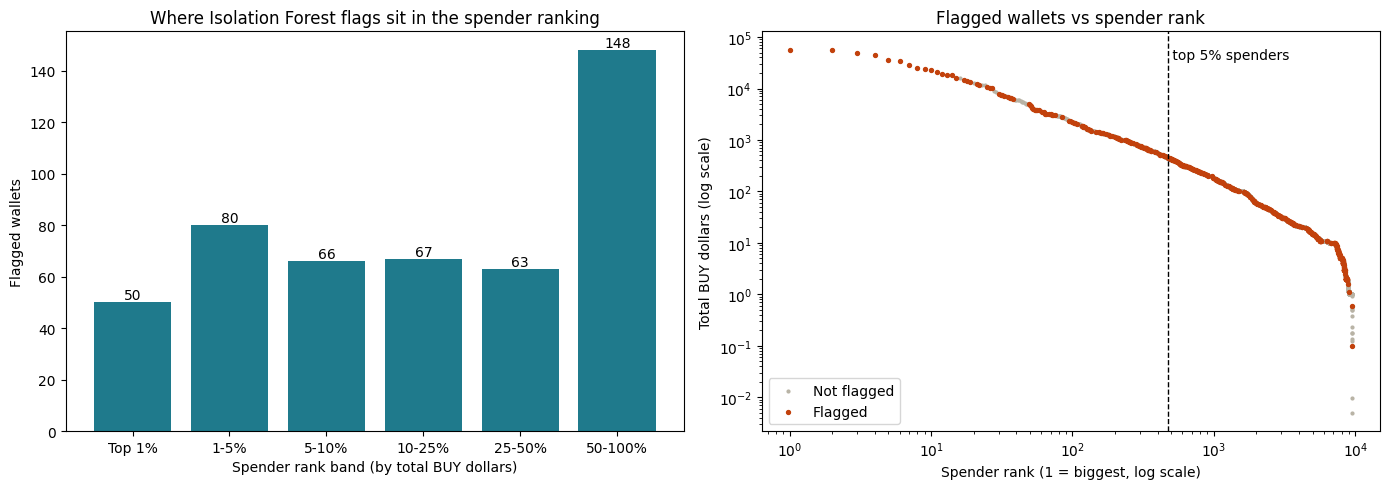

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Load wallet table (saved earlier by the notebook)
cands = [Path('datasets/behavioural_wallet_features_with_scores.parquet'),
         Path('../datasets/behavioural_wallet_features_with_scores.parquet')]
path = next(p for p in cands if p.exists())
w = pd.read_parquet(path)

# Rank wallets by total BUY dollars, 1 = biggest spender
w = w.sort_values('total_buy_dollars', ascending=False).reset_index(drop=True)
w['spender_rank'] = np.arange(1, len(w) + 1)
w['spender_pct'] = w['spender_rank'] / len(w) * 100
flag = w['behavioural_anomaly'].astype(bool)

# Table: where do the flagged wallets sit in the spender ranking
edges = [0, 1, 5, 10, 25, 50, 100]
labels = ['Top 1%', '1-5%', '5-10%', '10-25%', '25-50%', '50-100%']
w['band'] = pd.cut(w['spender_pct'], bins=edges, labels=labels, include_lowest=True)
tab = (w.groupby('band', observed=True)
         .agg(wallets=('wallet', 'size'),
              flagged=('behavioural_anomaly', 'sum'),
              buy_dollars=('total_buy_dollars', 'sum'),
              flagged_dollars=('total_buy_dollars', lambda s: s[flag.loc[s.index]].sum())))
tab['flagged_share_of_band_%'] = (tab['flagged'] / tab['wallets'] * 100).round(1)
tab['flagged_share_of_all_flagged_%'] = (tab['flagged'] / flag.sum() * 100).round(1)
tab['median_flagged_$'] = (w[flag].groupby('band', observed=True)['total_buy_dollars'].median().round(0))
print('Flagged wallets:', int(flag.sum()), 'of', len(w))
print(tab.round(0).to_string())

# Figure
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].bar(tab.index.astype(str), tab['flagged'], color='#1F7A8C')
for i, v in enumerate(tab['flagged']):
    ax[0].text(i, v, int(v), ha='center', va='bottom')
ax[0].set_xlabel('Spender rank band (by total BUY dollars)')
ax[0].set_ylabel('Flagged wallets')
ax[0].set_title('Where Isolation Forest flags sit in the spender ranking')

ax[1].scatter(w.loc[~flag, 'spender_rank'], w.loc[~flag, 'total_buy_dollars'],
              s=4, color='#B8B3A5', label='Not flagged')
ax[1].scatter(w.loc[flag, 'spender_rank'], w.loc[flag, 'total_buy_dollars'],
              s=8, color='#C2410C', label='Flagged')
ax[1].axvline(len(w) * 0.05, color='k', ls='--', lw=1)
ax[1].text(len(w) * 0.05, ax[1].get_ylim()[1], ' top 5% spenders', va='top')
ax[1].set_xscale('log'); ax[1].set_yscale('log')
ax[1].set_xlabel('Spender rank (1 = biggest, log scale)')
ax[1].set_ylabel('Total BUY dollars (log scale)')
ax[1].set_title('Flagged wallets vs spender rank')
ax[1].legend()
plt.tight_layout()
plt.show()

,n,mean,std,min,p01,p25,median,p75,p95,p99,max
position_anomaly_ratio,9467.0,0.948,0.222,0.013,0.308,1.0,1.000,1.000,1.034,1.602,4.580
market_notional_ratio,9467.0,0.001,0.004,0.000,0.000,0.0,0.000,0.000,0.002,0.018,0.123
avg_buy_price,9467.0,0.878,0.259,0.001,0.002,0.9,0.986,0.998,0.999,0.999,0.999
concentration,9467.0,0.954,0.146,0.078,0.333,1.0,1.000,1.000,1.000,1.000,1.000
wallet_age_days,9467.0,1.098,3.706,0.000,0.000,0.0,0.000,0.000,9.080,19.125,29.557
unique_markets,9467.0,1.215,1.040,1.000,1.000,1.0,1.000,1.000,2.000,4.000,15.000


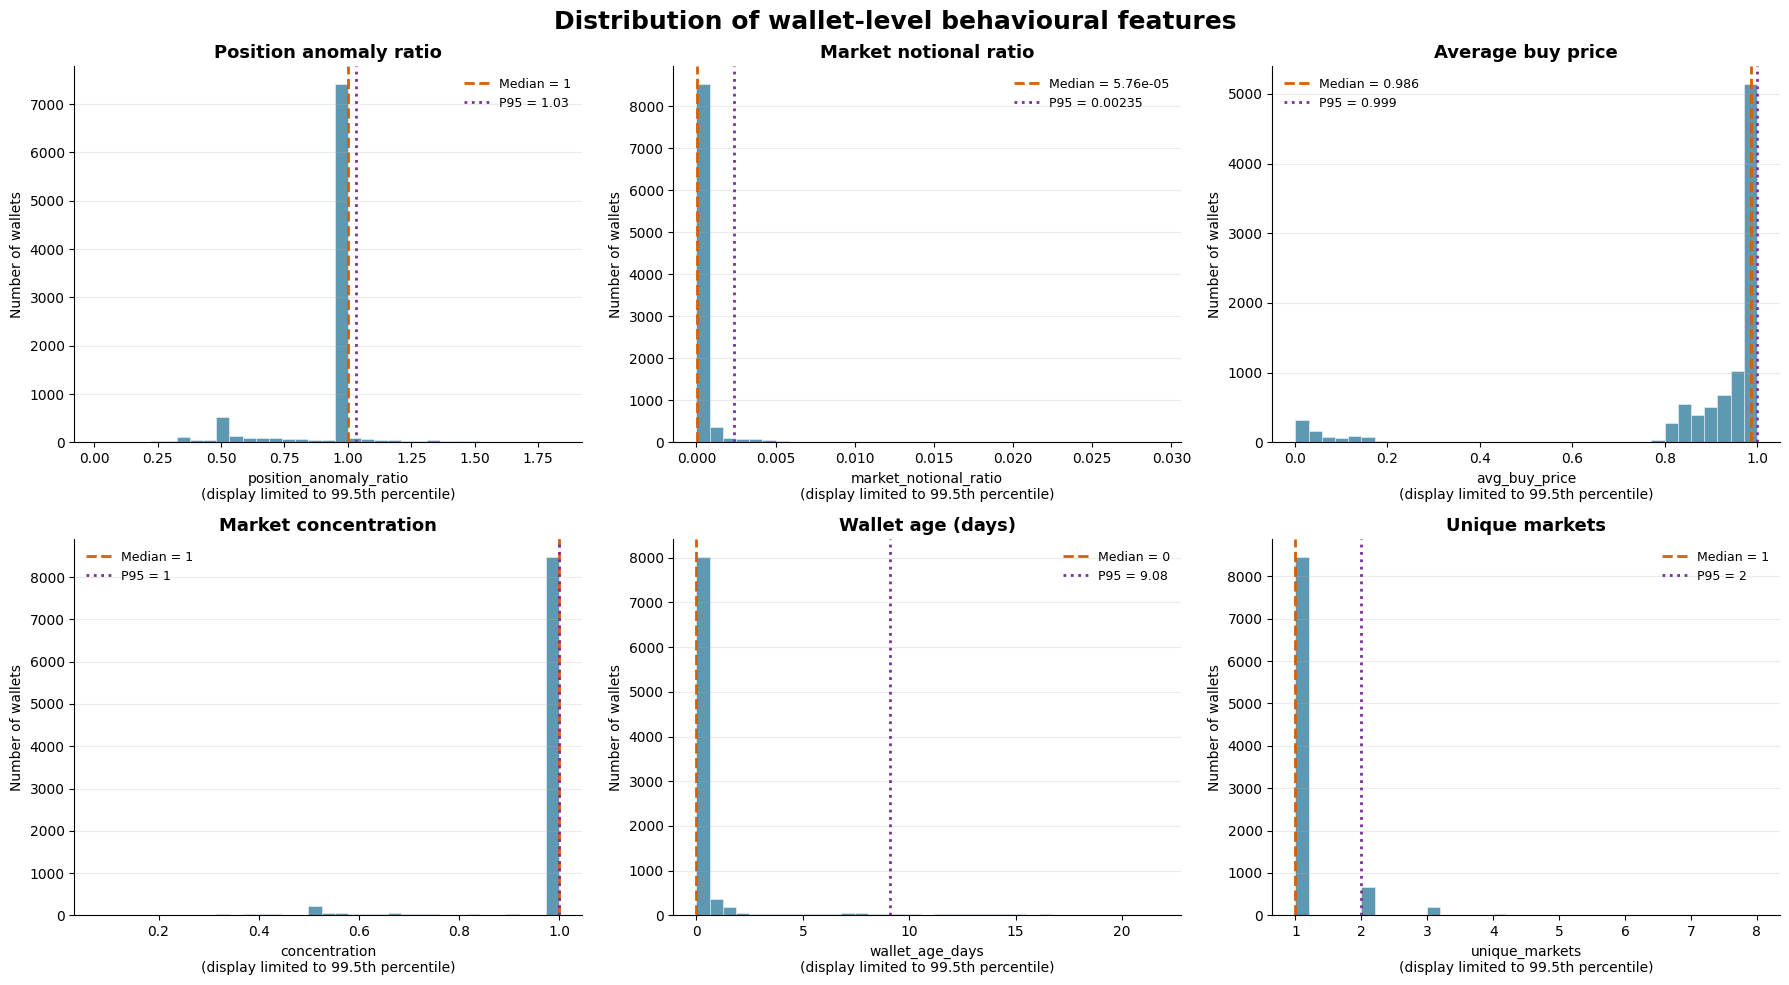

Figure saved to: /Users/zhongyangfan/Desktop/L3_prediction_markets_student_package_2026-10-07/notebooks/figures/15_six_feature_distributions.png


In [28]:
# EDA 1: Distribution of the six wallet-level behavioural features

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

feature_labels = {
    "position_anomaly_ratio": "Position anomaly ratio",
    "market_notional_ratio": "Market notional ratio",
    "avg_buy_price": "Average buy price",
    "concentration": "Market concentration",
    "wallet_age_days": "Wallet age (days)",
    "unique_markets": "Unique markets",
}

plot_cols = [
    "position_anomaly_ratio",
    "market_notional_ratio",
    "avg_buy_price",
    "concentration",
    "wallet_age_days",
    "unique_markets",
]

# Make sure numeric data is used
feature_data = wallet_features_beh[plot_cols].apply(
    pd.to_numeric,
    errors="coerce"
)

# Print descriptive statistics
feature_summary = (
    feature_data
    .describe(percentiles=[0.01, 0.25, 0.50, 0.75, 0.95, 0.99])
    .T
    .rename(columns={
        "count": "n",
        "mean": "mean",
        "std": "std",
        "min": "min",
        "1%": "p01",
        "25%": "p25",
        "50%": "median",
        "75%": "p75",
        "95%": "p95",
        "99%": "p99",
        "max": "max",
    })
)

display(feature_summary.round(3))

# Plot the distributions of the six features
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for ax, col in zip(axes, plot_cols):
    values = feature_data[col].dropna()

    if values.empty:
        ax.set_title(f"{feature_labels[col]} - no data")
        continue

    # To keep extreme values from compressing the main distribution, only limit the display range; no data is removed
    upper_display = values.quantile(0.995)
    values_display = values[values <= upper_display]

    ax.hist(
        values_display,
        bins=35,
        color="#3B82A0",
        alpha=0.82,
        edgecolor="white",
        linewidth=0.4
    )

    median_value = values.median()
    p95_value = values.quantile(0.95)

    ax.axvline(
        median_value,
        color="#D95F02",
        linestyle="--",
        linewidth=2,
        label=f"Median = {median_value:.3g}"
    )

    ax.axvline(
        p95_value,
        color="#7B3294",
        linestyle=":",
        linewidth=2,
        label=f"P95 = {p95_value:.3g}"
    )

    ax.set_title(feature_labels[col], fontsize=13, fontweight="bold")
    ax.set_xlabel(
        f"{col}\n(display limited to 99.5th percentile)",
        fontsize=10
    )
    ax.set_ylabel("Number of wallets")
    ax.grid(axis="y", alpha=0.25)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, fontsize=9)

fig.suptitle(
    "Distribution of wallet-level behavioural features",
    fontsize=18,
    fontweight="bold"
)

fig.tight_layout()

figure_path = FIGURE_DIR / "15_six_feature_distributions.png"
fig.savefig(
    figure_path,
    dpi=240,
    bbox_inches="tight"
)

plt.show()

print(f"Figure saved to: {figure_path}")

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

relationship_data = wallet_features_beh[
    [
        "wallet",
        "concentration",
        "unique_markets",
        "market_notional_ratio",
        "total_buy_dollars",
        "position_anomaly_ratio",
        "avg_spend_per_market",
        "wallet_age_days",
    ]
].replace(
    [np.inf, -np.inf],
    np.nan
).dropna()

plot_data = relationship_data.sample(
    min(5000, len(relationship_data)),
    random_state=42
).copy()

rng = np.random.default_rng(42)

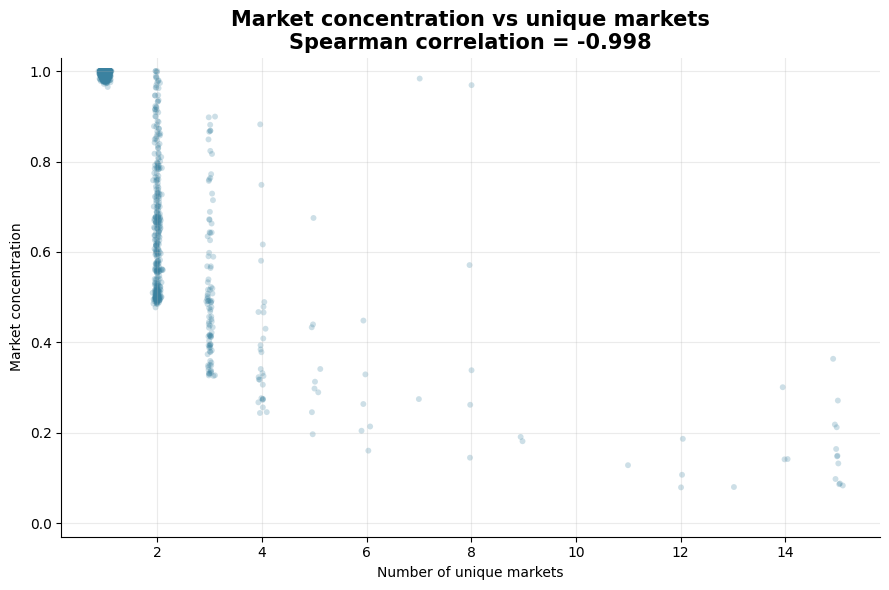

In [30]:
plot_df = plot_data.copy()

plot_df["unique_markets_jitter"] = (
    plot_df["unique_markets"]
    + rng.normal(0, 0.035, len(plot_df))
)

plot_df["concentration_jitter"] = (
    plot_df["concentration"]
    + rng.normal(0, 0.008, len(plot_df))
).clip(0, 1)

corr = relationship_data["concentration"].corr(
    relationship_data["unique_markets"],
    method="spearman"
)

fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    plot_df["unique_markets_jitter"],
    plot_df["concentration_jitter"],
    s=18,
    alpha=0.25,
    color="#3B82A0",
    edgecolors="none"
)

ax.set_title(
    f"Market concentration vs unique markets\n"
    f"Spearman correlation = {corr:.3f}",
    fontsize=15,
    fontweight="bold"
)
ax.set_xlabel("Number of unique markets")
ax.set_ylabel("Market concentration")
ax.set_ylim(-0.03, 1.03)
ax.grid(alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "16a_concentration_vs_unique_markets.png",
    dpi=240,
    bbox_inches="tight"
)

plt.show()

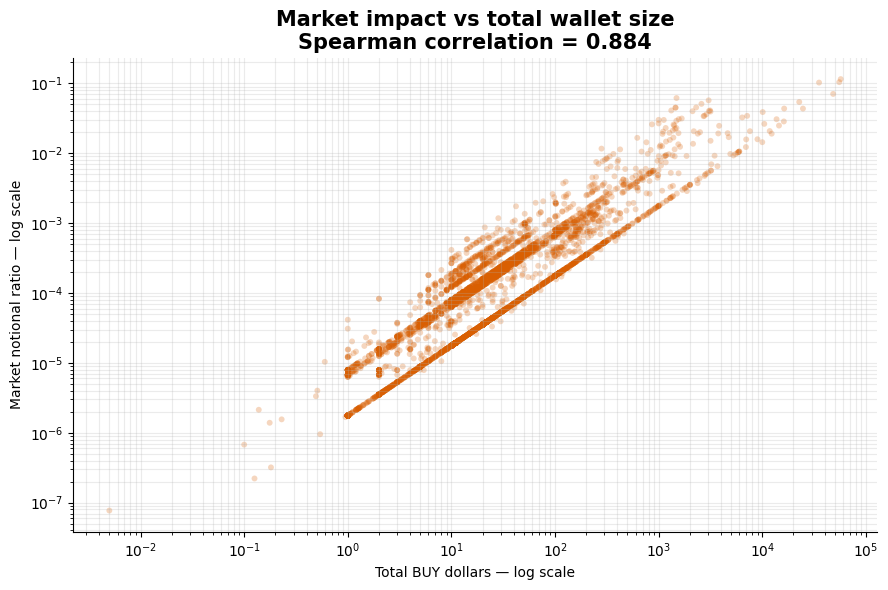

In [32]:
corr = relationship_data["market_notional_ratio"].corr(
    relationship_data["total_buy_dollars"],
    method="spearman"
)

fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    plot_data["total_buy_dollars"].clip(lower=1e-6),
    plot_data["market_notional_ratio"].clip(lower=1e-8),
    s=18,
    alpha=0.25,
    color="#D95F02",
    edgecolors="none"
)

ax.set_xscale("log")
ax.set_yscale("log")

ax.set_title(
    f"Market impact vs total wallet size\n"
    f"Spearman correlation = {corr:.3f}",
    fontsize=15,
    fontweight="bold"
)
ax.set_xlabel("Total BUY dollars — log scale")
ax.set_ylabel("Market notional ratio — log scale")
ax.grid(alpha=0.25, which="both")
ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "16b_market_impact_vs_wallet_size.png",
    dpi=240,
    bbox_inches="tight"
)

plt.show()

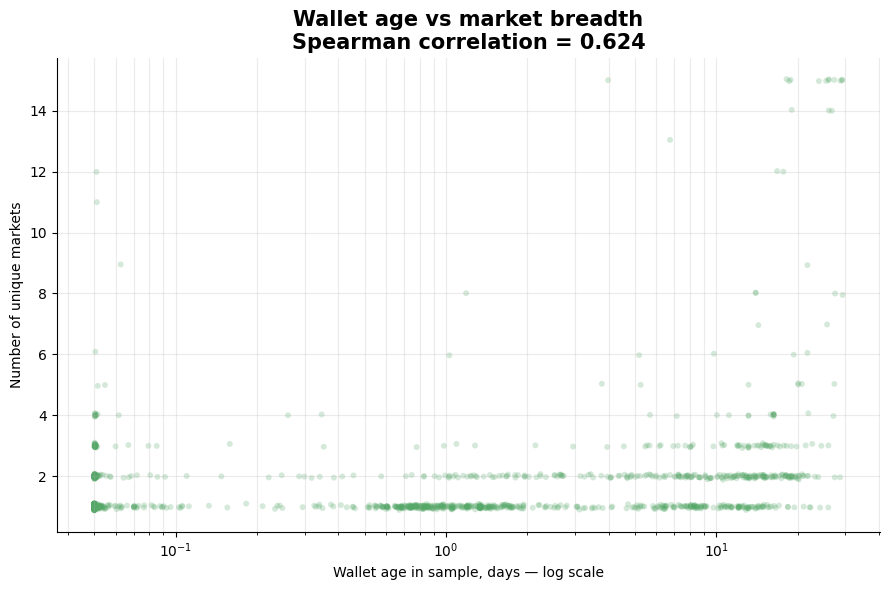

In [33]:
plot_df = plot_data.copy()

plot_df["unique_markets_jitter"] = (
    plot_df["unique_markets"]
    + rng.normal(0, 0.035, len(plot_df))
)

corr = relationship_data["wallet_age_days"].corr(
    relationship_data["unique_markets"],
    method="spearman"
)

fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    plot_df["wallet_age_days"] + 0.05,
    plot_df["unique_markets_jitter"],
    s=18,
    alpha=0.25,
    color="#55A868",
    edgecolors="none"
)

ax.set_xscale("log")

ax.set_title(
    f"Wallet age vs market breadth\n"
    f"Spearman correlation = {corr:.3f}",
    fontsize=15,
    fontweight="bold"
)
ax.set_xlabel("Wallet age in sample, days — log scale")
ax.set_ylabel("Number of unique markets")
ax.grid(alpha=0.25, which="both")
ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "16d_wallet_age_vs_unique_markets.png",
    dpi=240,
    bbox_inches="tight"
)

plt.show()

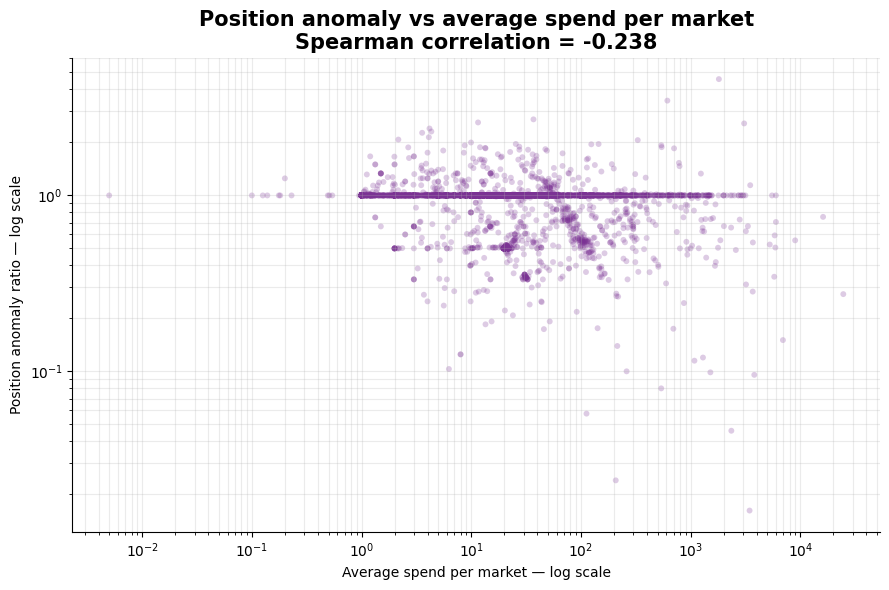

In [34]:
corr = relationship_data["position_anomaly_ratio"].corr(
    relationship_data["avg_spend_per_market"],
    method="spearman"
)

fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    plot_data["avg_spend_per_market"].clip(lower=1e-6),
    plot_data["position_anomaly_ratio"].clip(lower=1e-8),
    s=18,
    alpha=0.25,
    color="#7B3294",
    edgecolors="none"
)

ax.set_xscale("log")
ax.set_yscale("log")

ax.set_title(
    f"Position anomaly vs average spend per market\n"
    f"Spearman correlation = {corr:.3f}",
    fontsize=15,
    fontweight="bold"
)
ax.set_xlabel("Average spend per market — log scale")
ax.set_ylabel("Position anomaly ratio — log scale")
ax.grid(alpha=0.25, which="both")
ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "16c_position_anomaly_vs_average_spend.png",
    dpi=240,
    bbox_inches="tight"
)

plt.show()

In [42]:
print(wm.columns.tolist())

['wallet', 'market', 'direction', 'side_dollars', 'side_price', 'buy_dollars', 'n_trades', 'one_sided_share', 'hours_to_end', 'yes_outcome', 'win', 'excess']


In [43]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# =========================
# 1. Filter Anthropic markets
# =========================

anthropic = wm[
    wm["market"].astype(str).str.contains(
        "anthropic",
        case=False,
        na=False
    )
].copy()

# Numeric conversion
for col in ["buy_dollars", "side_price", "n_trades", "win", "excess"]:
    if col in anthropic.columns:
        anthropic[col] = pd.to_numeric(
            anthropic[col],
            errors="coerce"
        )

# Clean valid buy records
anthropic = anthropic[
    anthropic["wallet"].notna()
    & anthropic["buy_dollars"].notna()
    & (anthropic["buy_dollars"] > 0)
].copy()

print("Anthropic rows:", len(anthropic))
print("Unique wallets:", anthropic["wallet"].nunique())
print("Markets:", anthropic["market"].nunique())

Anthropic rows: 5369
Unique wallets: 5369
Markets: 1


In [44]:
def weighted_average(group):
    x = group["side_price"]
    w = group["buy_dollars"]
    valid = x.notna() & w.notna() & (w > 0)

    if valid.sum() == 0:
        return np.nan

    return np.average(
        x[valid],
        weights=w[valid]
    )

wallet_features_anthropic = (
    anthropic
    .groupby("wallet")
    .apply(
        lambda group: pd.Series({
            "total_buy_dollars": group["buy_dollars"].sum(),
            "n_trades": group["n_trades"].sum(),
            "avg_buy_price": weighted_average(group),
            "win_rate": group["win"].mean()
                if "win" in group.columns else np.nan,
            "excess_win_rate": group["excess"].mean()
                if "excess" in group.columns else np.nan,
        }),
        include_groups=False
    )
    .reset_index()
)

# Total invested in Anthropic markets
market_total_buy = (
    wallet_features_anthropic["total_buy_dollars"].sum()
)

# Wallet's share of total Anthropic BUY dollars
wallet_features_anthropic["market_notional_ratio"] = (
    wallet_features_anthropic["total_buy_dollars"]
    / market_total_buy
)

# Under Anthropic-only, these two variables carry no information
wallet_features_anthropic["concentration"] = 1.0
wallet_features_anthropic["unique_markets"] = 1

# There is only one market, so average investment per market = total investment
wallet_features_anthropic["avg_spend_per_market"] = (
    wallet_features_anthropic["total_buy_dollars"]
)

wallet_features_anthropic.head()

,wallet,total_buy_dollars,n_trades,avg_buy_price,win_rate,excess_win_rate,market_notional_ratio,concentration,unique_markets,avg_spend_per_market
0,0x0008d433ab85728f20d8da57bfff5187feccfbd7,10.879998,1.0,0.994000,1.0,0.006000,0.000019,1.0,1,10.879998
1,0x000dd715ae1dc4a7d25b18bbcc1eaae1dc82fb41,0.999998,1.0,0.984999,1.0,0.015001,0.000002,1.0,1,0.999998
2,0x00106a662bbacdfc181885124f6c764c18ab8daa,10.879998,1.0,0.994000,1.0,0.006000,0.000019,1.0,1,10.879998
3,0x001a75418f37750d65eb7abe44c4f845ffa333ed,1.999998,1.0,0.989000,1.0,0.011000,0.000004,1.0,1,1.999998
4,0x002e3b1ac9ab0d9035049a73f4f8b1f410a44174,10.879998,1.0,0.996000,1.0,0.004000,0.000019,1.0,1,10.879998


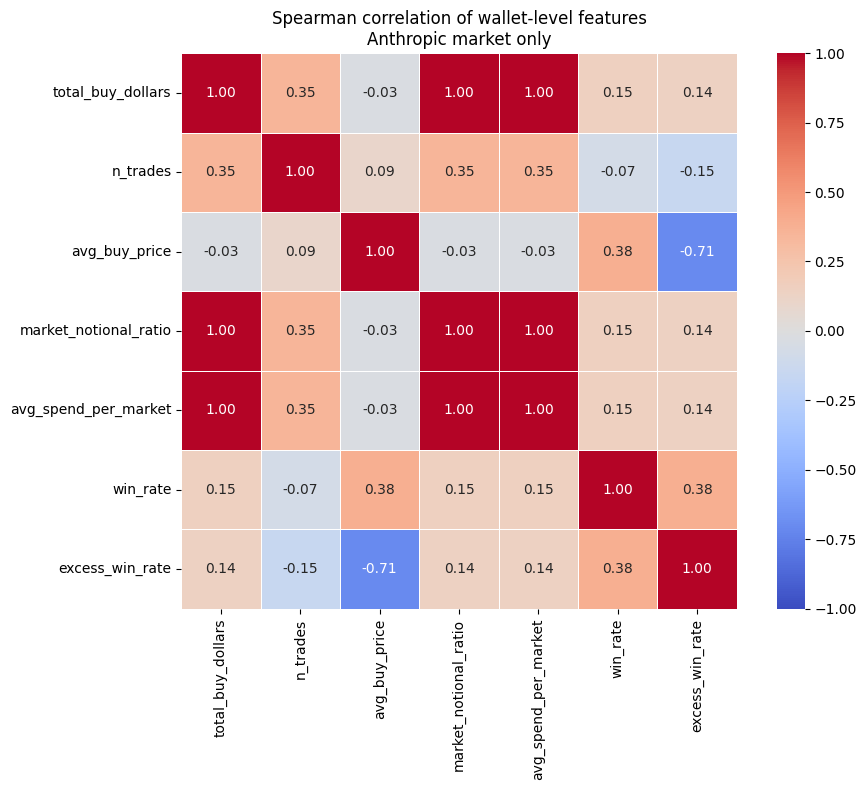

In [45]:
feature_cols = [
    "total_buy_dollars",
    "n_trades",
    "avg_buy_price",
    "market_notional_ratio",
    "avg_spend_per_market",
    "win_rate",
    "excess_win_rate",
]

# Drop constant columns and all-null columns
valid_cols = [
    col for col in feature_cols
    if col in wallet_features_anthropic.columns
    and wallet_features_anthropic[col].nunique(dropna=True) > 1
]

corr = wallet_features_anthropic[valid_cols].corr(
    method="spearman"
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5
)

plt.title(
    "Spearman correlation of wallet-level features\n"
    "Anthropic market only"
)

plt.tight_layout()
plt.show()

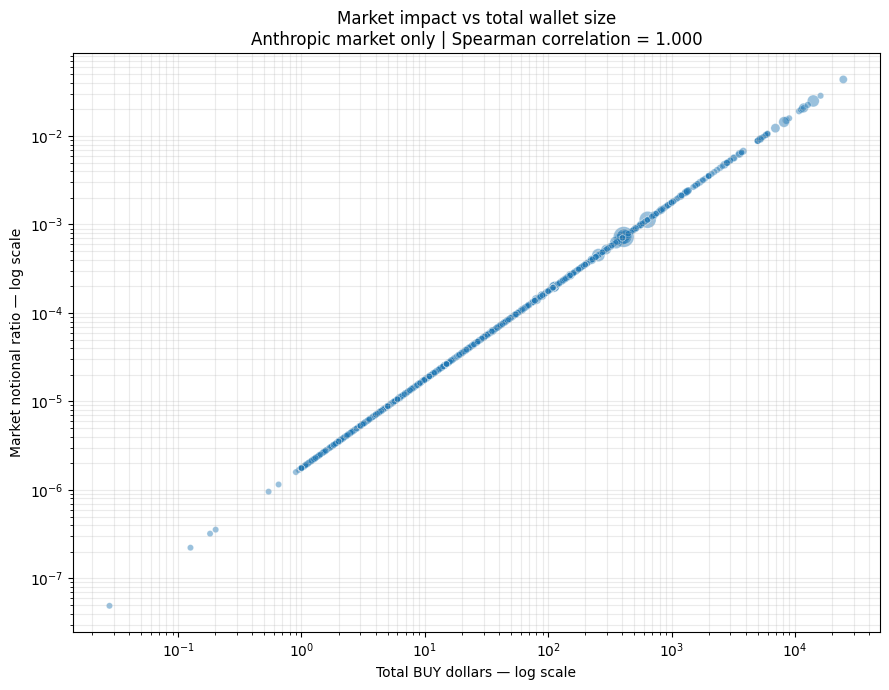

In [46]:
plot_df = wallet_features_anthropic[
    [
        "total_buy_dollars",
        "market_notional_ratio",
        "n_trades",
    ]
].replace([np.inf, -np.inf], np.nan).dropna()

plot_df = plot_df[
    (plot_df["total_buy_dollars"] > 0)
    & (plot_df["market_notional_ratio"] > 0)
]

rho = plot_df[
    ["total_buy_dollars", "market_notional_ratio"]
].corr(method="spearman").iloc[0, 1]

plt.figure(figsize=(9, 7))

sns.scatterplot(
    data=plot_df,
    x="total_buy_dollars",
    y="market_notional_ratio",
    size="n_trades",
    sizes=(20, 220),
    alpha=0.45,
    legend=False
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Total BUY dollars — log scale")
plt.ylabel("Market notional ratio — log scale")

plt.title(
    f"Market impact vs total wallet size\n"
    f"Anthropic market only | Spearman correlation = {rho:.3f}"
)

plt.grid(True, which="both", alpha=0.25)
plt.tight_layout()
plt.show()

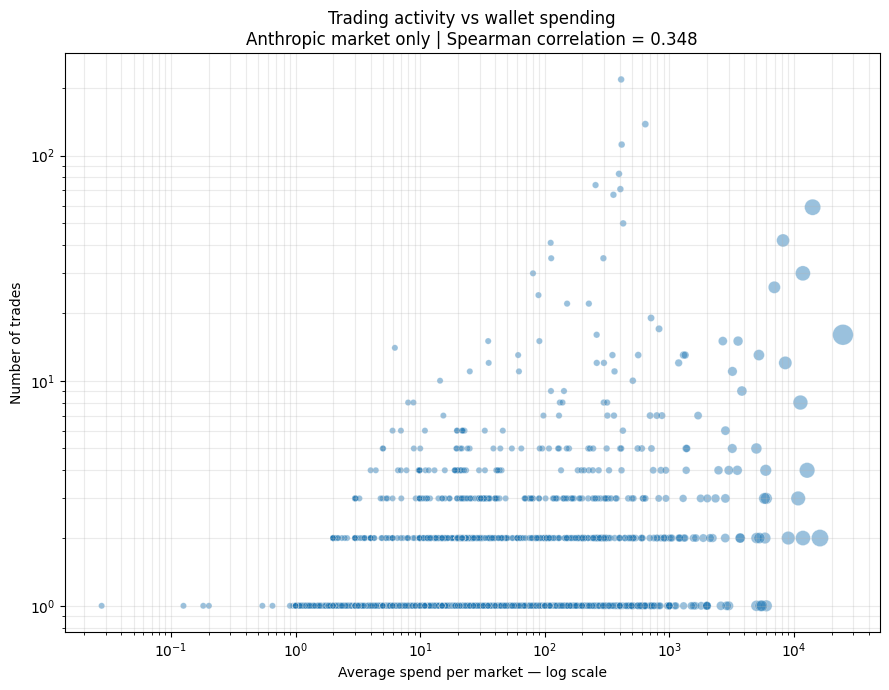

In [47]:
plot_df = wallet_features_anthropic[
    [
        "avg_spend_per_market",
        "n_trades",
        "total_buy_dollars",
    ]
].replace([np.inf, -np.inf], np.nan).dropna()

plot_df = plot_df[
    (plot_df["avg_spend_per_market"] > 0)
    & (plot_df["n_trades"] > 0)
]

rho = plot_df[
    ["avg_spend_per_market", "n_trades"]
].corr(method="spearman").iloc[0, 1]

plt.figure(figsize=(9, 7))

sns.scatterplot(
    data=plot_df,
    x="avg_spend_per_market",
    y="n_trades",
    size="total_buy_dollars",
    sizes=(20, 220),
    alpha=0.45,
    legend=False
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Average spend per market — log scale")
plt.ylabel("Number of trades")

plt.title(
    f"Trading activity vs wallet spending\n"
    f"Anthropic market only | Spearman correlation = {rho:.3f}"
)

plt.grid(True, which="both", alpha=0.25)
plt.tight_layout()
plt.show()